
# Brain Tumor Segmentation Using MRI
## A Comparative Study of U-Net and SegFormer Architectures

**Project Domain:** Artificial Intelligence | Deep Learning | Medical Image Segmentation

---

## 1. Introduction

Brain tumor segmentation is an important task in medical image analysis. It aims to identify and delineate tumor regions in Magnetic Resonance Imaging (MRI) scans at the pixel level. Accurate segmentation can help researchers analyze tumor location, shape, and spatial extent.

Manual segmentation of MRI scans can be time-consuming and may vary between annotators. Deep learning-based segmentation methods provide an opportunity to automate this process by learning spatial patterns from labeled medical images.

In this project, we develop and evaluate deep learning models for brain tumor segmentation using MRI images and their corresponding ground-truth masks. The main goal is to compare different model architectures and investigate how pretrained representations affect segmentation performance.

## 2. Problem Statement

The task is formulated as a binary image segmentation problem. Given an MRI image, the model predicts a binary mask in which each pixel is classified as either part of the annotated tumor region or background.

The project also considers images with empty ground-truth masks. These cases are important for evaluating whether a model incorrectly predicts tumor pixels when the reference mask contains no tumor annotation.

## 3. Project Objectives

The main objectives are:

1. Develop a baseline U-Net model trained from scratch.
2. Implement a pretrained U-Net using a ResNet34 encoder.
3. Implement SegFormer-B0 as a transformer-based segmentation approach.
4. Evaluate the models using Positive Dice, Positive Intersection over Union (IoU), and Empty-mask False Positive Rate (FPR).
5. Select the operating threshold using the validation set and reserve the test set for final evaluation.
6. Compare quantitative results and visually inspect segmentation predictions, including difficult cases.
7. Document the experimental workflow, results, and limitations.

## 4. Dataset Overview

The project uses the LGG MRI Segmentation dataset, containing brain MRI images and corresponding binary tumor masks.

The dataset contains 3,929 paired MRI images and masks from 110 patients. The images are processed at a resolution of 256 × 256 pixels.

The dataset includes both positive masks, which contain annotated tumor pixels, and empty masks, which contain no annotated tumor region. Because multiple images may come from the same patient, the data is split at the patient level to reduce data leakage between training, validation, and test sets.

## 5. Methodology

The experimental workflow consists of the following stages:

1. **Data Preparation:** Load MRI images and their corresponding masks, validate image-mask pairs, and prepare the binary segmentation targets.
2. **Patient-Level Data Splitting:** Create separate training, validation, and test sets without patient overlap.
3. **Model Development:** Train a U-Net baseline from scratch, a pretrained U-Net with a ResNet34 encoder, and SegFormer-B0.
4. **Model Selection:** Select the best checkpoint using validation performance.
5. **Threshold Selection:** Choose a probability threshold using validation data only.
6. **Final Evaluation:** Evaluate each selected model on the held-out test set.
7. **Comparative Analysis:** Compare quantitative metrics and inspect visual overlays of ground-truth masks and predicted masks.

## 6. Evaluation Metrics

- **Positive Dice Score:** Measures the overlap between predicted and ground-truth tumor masks on images with positive ground-truth masks. Higher values indicate better overlap.
- **Positive IoU:** Measures the intersection over the union of predicted and ground-truth masks on positive images. Higher values indicate better overlap.
- **Empty-mask FPR:** Measures the proportion of images with empty ground-truth masks for which the model predicts at least one tumor pixel. Lower values indicate fewer false-positive predictions on empty-mask images.

## 7. Experimental Scope and Limitations

This study evaluates segmentation performance on a single dataset using a patient-level split. The results depend on the dataset, preprocessing pipeline, model checkpoints, and selected probability thresholds.

The experiment is intended for academic research and educational purposes. It does not establish clinical validity, and the models are not intended to replace medical professionals or provide independent medical diagnoses.

## 8. Project Structure

The notebook is organized into the following stages:

- Dataset inspection and exploratory analysis
- Data preprocessing and patient-level splitting
- U-Net baseline implementation and evaluation
- Pretrained U-Net implementation and evaluation
- SegFormer-B0 implementation and evaluation
- Final model comparison and hard-case analysis
- Conclusions and limitations


In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected — check Runtime settings.")

PyTorch version: 2.14.0+cu126
CUDA available: True
GPU: Quadro P2000


In [ ]:
!pip -q install kaggle

import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)

shutil.copy(
    "/content/kaggle.json",
    "/root/.kaggle/kaggle.json"
)

os.chmod("/root/.kaggle/kaggle.json", 0o600)

!kaggle datasets download \
    -d mateuszbuda/lgg-mri-segmentation \
    -p /content/brain_tumor_data \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/mateuszbuda/lgg-mri-segmentation
License(s): CC-BY-NC-SA-4.0
100% 714M/714M [00:05<00:00, 144MB/s]



In [ ]:
import os

DATA_ROOT = "/content/brain_tumor_data"

for root, dirs, files in os.walk(DATA_ROOT):
    images = [f for f in files if f.lower().endswith((".tif", ".tiff", ".png", ".jpg", ".jpeg"))]

    if images:
        print(f"Folder: {root}")
        print(f"Number of image files: {len(images)}")
        print(f"Samples: {images[:3]}")
        print("-" * 50)

Folder: /content/brain_tumor_data/kaggle_3m/TCGA_DU_A5TP_19970614
Number of image files: 76
Samples: ['TCGA_DU_A5TP_19970614_2_mask.tif', 'TCGA_DU_A5TP_19970614_14.tif', 'TCGA_DU_A5TP_19970614_27_mask.tif']
--------------------------------------------------
Folder: /content/brain_tumor_data/kaggle_3m/TCGA_FG_A4MU_20030903
Number of image files: 72
Samples: ['TCGA_FG_A4MU_20030903_31.tif', 'TCGA_FG_A4MU_20030903_5.tif', 'TCGA_FG_A4MU_20030903_9_mask.tif']
--------------------------------------------------
Folder: /content/brain_tumor_data/kaggle_3m/TCGA_HT_7694_19950404
Number of image files: 42
Samples: ['TCGA_HT_7694_19950404_8_mask.tif', 'TCGA_HT_7694_19950404_3_mask.tif', 'TCGA_HT_7694_19950404_19_mask.tif']
--------------------------------------------------
Folder: /content/brain_tumor_data/kaggle_3m/TCGA_FG_7643_20021104
Number of image files: 96
Samples: ['TCGA_FG_7643_20021104_22.tif', 'TCGA_FG_7643_20021104_48.tif', 'TCGA_FG_7643_20021104_5.tif']
-------------------------------

In [ ]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

DATA_ROOT = "/content/brain_tumor_data/kaggle_3m"

# Find MRI images and exclude masks
image_paths = glob.glob(
    os.path.join(DATA_ROOT, "**", "*.tif"),
    recursive=True
)

image_paths = [
    p for p in image_paths
    if not p.lower().endswith("_mask.tif")
]

print("MRI images found:", len(image_paths))

# Find images that have matching masks
paired_images = []

for image_path in image_paths:
    mask_path = image_path[:-4] + "_mask.tif"

    if os.path.exists(mask_path):
        paired_images.append((image_path, mask_path))

print("Images with matching masks:", len(paired_images))

if paired_images:
    print("\nSample image:", paired_images[0][0])
    print("Sample mask:", paired_images[0][1])
else:
    print("No matching pairs found. Check the dataset folder.")

MRI images found: 3929
Images with matching masks: 3929

Sample image: /content/brain_tumor_data/kaggle_3m/TCGA_DU_A5TP_19970614/TCGA_DU_A5TP_19970614_14.tif
Sample mask: /content/brain_tumor_data/kaggle_3m/TCGA_DU_A5TP_19970614/TCGA_DU_A5TP_19970614_14_mask.tif


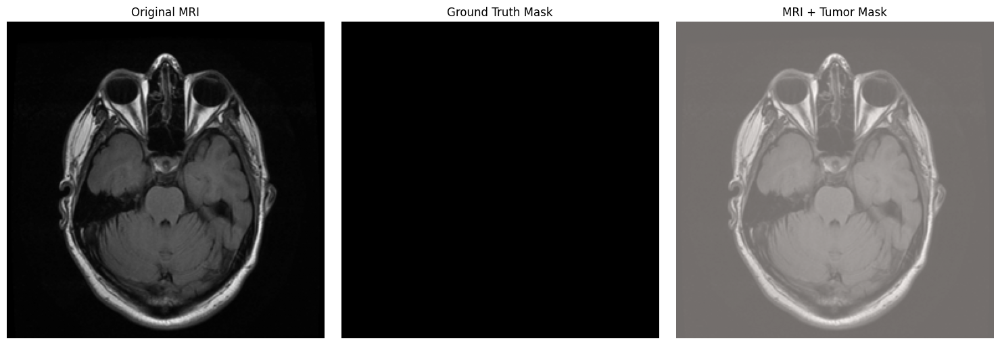

MRI shape: (256, 256)
Mask shape: (256, 256)
Tumor pixels: 0


In [ ]:
# Display a sample MRI and its corresponding mask
if paired_images:
    image_path, mask_path = paired_images[0]

    mri = np.array(Image.open(image_path).convert("L"))
    mask = np.array(Image.open(mask_path).convert("L"))

    # Convert mask to binary
    mask_binary = mask > 0

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(mri, cmap="gray")
    plt.title("Original MRI")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(mask_binary, cmap="gray")
    plt.title("Ground Truth Mask")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(mri, cmap="gray")
    plt.imshow(mask_binary, cmap="Reds", alpha=0.45)
    plt.title("MRI + Tumor Mask")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("MRI shape:", mri.shape)
    print("Mask shape:", mask.shape)
    print("Tumor pixels:", int(mask_binary.sum()))
else:
    print("Run Step 1 and check the matching pairs count.")

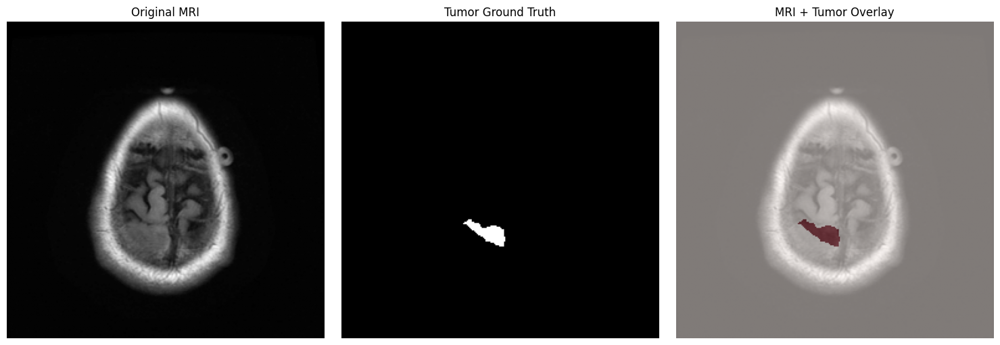

MRI: /content/brain_tumor_data/kaggle_3m/TCGA_DU_A5TP_19970614/TCGA_DU_A5TP_19970614_33.tif
Tumor pixels: 332
Tumor area (%): 0.51


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

tumor_pair = None

for image_path, mask_path in paired_images:
    mask = np.array(Image.open(mask_path).convert("L"))

    if np.any(mask > 0):
        tumor_pair = (image_path, mask_path)
        break

if tumor_pair:
    image_path, mask_path = tumor_pair

    mri = np.array(Image.open(image_path).convert("L"))
    mask = np.array(Image.open(mask_path).convert("L"))
    mask_binary = mask > 0

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(mri, cmap="gray")
    axes[0].set_title("Original MRI")

    axes[1].imshow(mask_binary, cmap="gray")
    axes[1].set_title("Tumor Ground Truth")

    axes[2].imshow(mri, cmap="gray")
    axes[2].imshow(mask_binary, cmap="Reds", alpha=0.5)
    axes[2].set_title("MRI + Tumor Overlay")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    print("MRI:", image_path)
    print("Tumor pixels:", int(mask_binary.sum()))
    print("Tumor area (%):", round(mask_binary.mean() * 100, 2))
else:
    print("No positive masks found. We need to inspect the masks.")

In [ ]:
import os
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

DATA_ROOT = "/content/brain_tumor_data/kaggle_3m"

# Find all MRI images, excluding masks
image_paths = []

for root, dirs, files in os.walk(DATA_ROOT):
    for filename in files:
        if filename.lower().endswith(".tif") and not filename.lower().endswith("_mask.tif"):
            image_paths.append(os.path.join(root, filename))

records = []

for image_path in tqdm(sorted(image_paths), desc="Analyzing dataset"):
    mask_path = image_path[:-4] + "_mask.tif"

    if not os.path.exists(mask_path):
        continue

    mask = np.array(Image.open(mask_path).convert("L"))
    binary_mask = mask > 0

    records.append({
        "patient": os.path.basename(os.path.dirname(image_path)),
        "image_path": image_path,
        "mask_path": mask_path,
        "height": mask.shape[0],
        "width": mask.shape[1],
        "tumor_pixels": int(binary_mask.sum()),
        "tumor_area_pct": float(binary_mask.mean() * 100),
        "has_tumor": bool(binary_mask.any())
    })

df = pd.DataFrame(records)

print("Total matched MRI-mask pairs:", len(df))
print("Unique patients:", df["patient"].nunique())
print("Images with tumor:", int(df["has_tumor"].sum()))
print("Images with empty masks:", int((~df["has_tumor"]).sum()))

print("\nTumor distribution:")
print(df["has_tumor"].value_counts())

print("\nTumor area statistics (%):")
print(df.loc[df["has_tumor"], "tumor_area_pct"].describe())

df.head()

Analyzing dataset:   0%|          | 0/3929 [00:00<?, ?it/s]

Total matched MRI-mask pairs: 3929
Unique patients: 110
Images with tumor: 1373
Images with empty masks: 2556

Tumor distribution:
has_tumor
False    2556
True     1373
Name: count, dtype: int64

Tumor area statistics (%):
count    1373.000000
mean        2.947129
std         2.334002
min         0.010681
25%         1.121521
50%         2.333069
75%         4.219055
max        12.098694
Name: tumor_area_pct, dtype: float64


,patient,image_path,mask_path,height,width,tumor_pixels,tumor_area_pct,has_tumor
0,TCGA_CS_4941_19960909,/content/brain_tumor_data/kaggle_3m/TCGA_CS_49...,/content/brain_tumor_data/kaggle_3m/TCGA_CS_49...,256,256,0,0.000000,False
1,TCGA_CS_4941_19960909,/content/brain_tumor_data/kaggle_3m/TCGA_CS_49...,/content/brain_tumor_data/kaggle_3m/TCGA_CS_49...,256,256,0,0.000000,False
2,TCGA_CS_4941_19960909,/content/brain_tumor_data/kaggle_3m/TCGA_CS_49...,/content/brain_tumor_data/kaggle_3m/TCGA_CS_49...,256,256,1426,2.175903,True
3,TCGA_CS_4941_19960909,/content/brain_tumor_data/kaggle_3m/TCGA_CS_49...,/content/brain_tumor_data/kaggle_3m/TCGA_CS_49...,256,256,2646,4.037476,True
4,TCGA_CS_4941_19960909,/content/brain_tumor_data/kaggle_3m/TCGA_CS_49...,/content/brain_tumor_data/kaggle_3m/TCGA_CS_49...,256,256,2765,4.219055,True


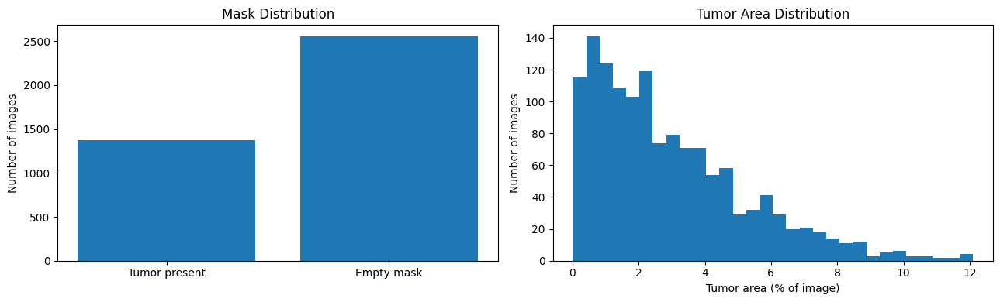

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

counts = df["has_tumor"].value_counts().reindex(
    [True, False], fill_value=0
)

axes[0].bar(
    ["Tumor present", "Empty mask"],
    counts.values
)
axes[0].set_title("Mask Distribution")
axes[0].set_ylabel("Number of images")

positive_areas = df.loc[df["has_tumor"], "tumor_area_pct"]

axes[1].hist(positive_areas, bins=30)
axes[1].set_title("Tumor Area Distribution")
axes[1].set_xlabel("Tumor area (% of image)")
axes[1].set_ylabel("Number of images")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

SEED = 42

# One row per patient, with patient-level tumor presence
patient_df = (
    df.groupby("patient")["has_tumor"]
    .max()
    .reset_index()
)

# First split: 70% train, 30% remaining
train_patients, remaining_patients = train_test_split(
    patient_df,
    test_size=0.30,
    random_state=SEED,
    stratify=patient_df["has_tumor"]
)

# Split remaining patients equally into validation and test
val_patients, test_patients = train_test_split(
    remaining_patients,
    test_size=0.50,
    random_state=SEED,
    stratify=remaining_patients["has_tumor"]
)

train_ids = set(train_patients["patient"])
val_ids = set(val_patients["patient"])
test_ids = set(test_patients["patient"])

train_df = df[df["patient"].isin(train_ids)].copy()
val_df = df[df["patient"].isin(val_ids)].copy()
test_df = df[df["patient"].isin(test_ids)].copy()

# Leakage checks
assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("Patient-level split: PASSED")
print(f"Train: {len(train_df)} images | {len(train_ids)} patients")
print(f"Validation: {len(val_df)} images | {len(val_ids)} patients")
print(f"Test: {len(test_df)} images | {len(test_ids)} patients")

print("\nTumor distribution by split:")
for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        f"{name}: {part['has_tumor'].sum()} positive, "
        f"{(~part['has_tumor']).sum()} empty masks"
    )

Patient-level split: PASSED
Train: 2760 images | 77 patients
Validation: 646 images | 16 patients
Test: 523 images | 17 patients

Tumor distribution by split:
Train: 994 positive, 1766 empty masks
Validation: 206 positive, 440 empty masks
Test: 173 positive, 350 empty masks


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np

class BrainTumorDataset(Dataset):
    def __init__(self, dataframe):
        self.data = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        image = Image.open(row["image_path"]).convert("L")
        mask = Image.open(row["mask_path"]).convert("L")

        image = np.array(image, dtype=np.float32) / 255.0
        mask = (np.array(mask) > 0).astype(np.float32)

        # Add channel dimension: [1, H, W]
        image = torch.from_numpy(image).unsqueeze(0)
        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask


BATCH_SIZE = 8

train_dataset = BrainTumorDataset(train_df)
val_dataset = BrainTumorDataset(val_df)
test_dataset = BrainTumorDataset(test_df)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=2, pin_memory=True
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2, pin_memory=True
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2, pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 345
Validation batches: 81
Test batches: 66


Image batch shape: torch.Size([8, 1, 256, 256])
Mask batch shape: torch.Size([8, 1, 256, 256])
Image dtype: torch.float32
Mask unique values: [0.0, 1.0]
Image range: 0.0 0.9607843160629272
Mask range: 0.0 1.0


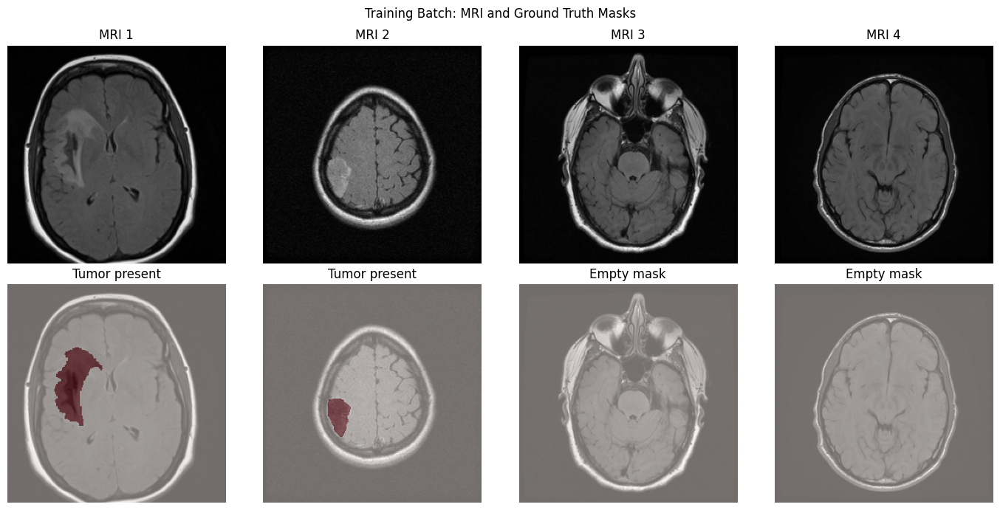

In [ ]:
import matplotlib.pyplot as plt

images, masks = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)
print("Image dtype:", images.dtype)
print("Mask unique values:", torch.unique(masks).tolist())
print("Image range:", images.min().item(), images.max().item())
print("Mask range:", masks.min().item(), masks.max().item())

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i in range(4):
    axes[0, i].imshow(images[i, 0].numpy(), cmap="gray")
    axes[0, i].set_title(f"MRI {i+1}")
    axes[0, i].axis("off")

    axes[1, i].imshow(images[i, 0].numpy(), cmap="gray")
    axes[1, i].imshow(
        masks[i, 0].numpy(),
        cmap="Reds", alpha=0.45, vmin=0, vmax=1
    )
    axes[1, i].set_title(
        "Tumor present" if masks[i].sum() > 0 else "Empty mask"
    )
    axes[1, i].axis("off")

plt.suptitle("Training Batch: MRI and Ground Truth Masks")
plt.tight_layout()
plt.show()

Image batch shape: torch.Size([8, 1, 256, 256])
Mask batch shape: torch.Size([8, 1, 256, 256])
Image dtype: torch.float32
Mask unique values: [0.0, 1.0]
Image range: 0.0 0.9372549057006836
Mask range: 0.0 1.0


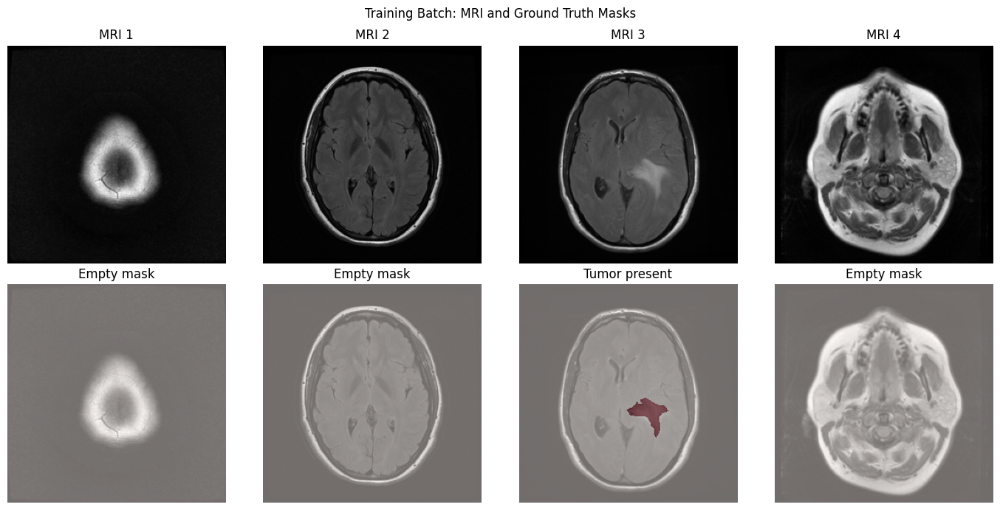

In [ ]:
import matplotlib.pyplot as plt

images, masks = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)
print("Image dtype:", images.dtype)
print("Mask unique values:", torch.unique(masks).tolist())
print("Image range:", images.min().item(), images.max().item())
print("Mask range:", masks.min().item(), masks.max().item())

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i in range(4):
    axes[0, i].imshow(images[i, 0].numpy(), cmap="gray")
    axes[0, i].set_title(f"MRI {i+1}")
    axes[0, i].axis("off")

    axes[1, i].imshow(images[i, 0].numpy(), cmap="gray")
    axes[1, i].imshow(
        masks[i, 0].numpy(),
        cmap="Reds", alpha=0.45, vmin=0, vmax=1
    )
    axes[1, i].set_title(
        "Tumor present" if masks[i].sum() > 0 else "Empty mask"
    )
    axes[1, i].axis("off")

plt.suptitle("Training Batch: MRI and Ground Truth Masks")
plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
import json
import random
import numpy as np
import pandas as pd
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PROJECT_DIR = "/content/drive/MyDrive/BrainTumorSegmentation"
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0))
print("Project directory:", PROJECT_DIR)
print("Checkpoint directory:", CHECKPOINT_DIR)

Mounted at /content/drive
Device: cuda
GPU: Tesla T4
Project directory: /content/drive/MyDrive/BrainTumorSegmentation
Checkpoint directory: /content/drive/MyDrive/BrainTumorSegmentation/checkpoints


In [ ]:
import torch.nn as nn
import torch.nn.functional as F

def dice_loss(logits, targets, smooth=1.0):
    probs = torch.sigmoid(logits)

    probs = probs.flatten(start_dim=1)
    targets = targets.flatten(start_dim=1)

    intersection = (probs * targets).sum(dim=1)

    dice = (
        2.0 * intersection + smooth
    ) / (
        probs.sum(dim=1) + targets.sum(dim=1) + smooth
    )

    return 1.0 - dice.mean()


class DiceBCELoss(nn.Module):
    def __init__(self, bce_weight=0.5, dice_weight=0.5):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.bce_weight = bce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):
        return (
            self.bce_weight * self.bce(logits, targets)
            + self.dice_weight * dice_loss(logits, targets)
        )


criterion = DiceBCELoss()

print("Loss function:", criterion)
print("Training device:", device)

Loss function: DiceBCELoss(
  (bce): BCEWithLogitsLoss()
)
Training device: cuda


In [ ]:
import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.layers(x)


class UNet(nn.Module):
    def __init__(self, in_channels=1, out_channels=1):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        self.enc1 = DoubleConv(in_channels, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.enc4 = DoubleConv(128, 256)

        self.bottleneck = DoubleConv(256, 512)

        self.up4 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec4 = DoubleConv(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = DoubleConv(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = DoubleConv(64, 32)

        self.final = nn.Conv2d(32, out_channels, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.final(d1)


print("U-Net architecture defined successfully.")

U-Net architecture defined successfully.


In [ ]:
import torch.nn as nn
import torch.nn.functional as F

def dice_loss(logits, targets, smooth=1.0):
    probs = torch.sigmoid(logits)

    probs = probs.flatten(start_dim=1)
    targets = targets.flatten(start_dim=1)

    intersection = (probs * targets).sum(dim=1)

    dice = (
        2.0 * intersection + smooth
    ) / (
        probs.sum(dim=1) + targets.sum(dim=1) + smooth
    )

    return 1.0 - dice.mean()


class DiceBCELoss(nn.Module):
    def __init__(self, bce_weight=0.5, dice_weight=0.5):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.bce_weight = bce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):
        return (
            self.bce_weight * self.bce(logits, targets)
            + self.dice_weight * dice_loss(logits, targets)
        )


criterion = DiceBCELoss()

print("Loss function:", criterion)
print("Training device:", device)

Loss function: DiceBCELoss(
  (bce): BCEWithLogitsLoss()
)
Training device: cuda


In [ ]:
model = UNet(in_channels=1, out_channels=1).to(device)

images, masks = next(iter(train_loader))
images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    logits = model(images)
    loss = criterion(logits, masks)

print("Input shape:", images.shape)
print("Output shape:", logits.shape)
print("Initial loss:", round(loss.item(), 4))
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

assert logits.shape == masks.shape
assert torch.isfinite(loss)

print("Pre-training checks: PASSED")

Input shape: torch.Size([8, 1, 256, 256])
Output shape: torch.Size([8, 1, 256, 256])
Initial loss: 0.9883
Trainable parameters: 7762465
Pre-training checks: PASSED


In [ ]:
import time
from tqdm.auto import tqdm

BEST_MODEL_PATH = os.path.join(CHECKPOINT_DIR, "unet_from_scratch_best.pth")
HISTORY_PATH = os.path.join(RESULTS_DIR, "unet_from_scratch_history.csv")

EPOCHS = 20
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
THRESHOLD = 0.5

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=2
)

amp_enabled = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)

best_positive_dice = -1.0
history = []

def evaluate(loader):
    model.eval()

    total_loss = 0.0
    positive_dices = []
    empty_false_positives = 0
    empty_count = 0

    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=amp_enabled
            ):
                logits = model(images)
                loss = criterion(logits, masks)

            total_loss += loss.item() * images.size(0)

            predictions = torch.sigmoid(logits.float()) >= THRESHOLD

            for i in range(images.size(0)):
                pred = predictions[i]
                target = masks[i] >= 0.5

                if target.any():
                    intersection = (pred & target).sum().item()
                    denominator = pred.sum().item() + target.sum().item()

                    dice = (2 * intersection + 1e-7) / (
                        denominator + 1e-7
                    )
                    positive_dices.append(dice)
                else:
                    empty_count += 1
                    if pred.any():
                        empty_false_positives += 1

    return {
        "loss": total_loss / len(loader.dataset),
        "positive_dice": float(np.mean(positive_dices)) if positive_dices else 0.0,
        "empty_mask_fpr": (
            empty_false_positives / empty_count if empty_count else 0.0
        ),
        "positive_images": len(positive_dices),
        "empty_images": empty_count
    }


for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    start_time = time.time()

    progress = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}")

    for images, masks in progress:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=amp_enabled
        ):
            logits = model(images)
            loss = criterion(logits, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)

        progress.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = running_loss / len(train_loader.dataset)
    val_metrics = evaluate(val_loader)

    scheduler.step(val_metrics["positive_dice"])

    epoch_time = time.time() - start_time

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_metrics["loss"],
        "val_positive_dice": val_metrics["positive_dice"],
        "val_empty_mask_fpr": val_metrics["empty_mask_fpr"],
        "learning_rate": optimizer.param_groups[0]["lr"],
        "epoch_seconds": epoch_time
    }

    history.append(record)
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    is_best = val_metrics["positive_dice"] > best_positive_dice

    if is_best:
        best_positive_dice = val_metrics["positive_dice"]

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_positive_dice": best_positive_dice,
            "config": {
                "seed": SEED,
                "epochs": EPOCHS,
                "learning_rate": LEARNING_RATE,
                "threshold": THRESHOLD,
                "model": "UNet from scratch"
            }
        }, BEST_MODEL_PATH)

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Positive Dice: {val_metrics['positive_dice']:.4f} | "
        f"Empty-mask FPR: {val_metrics['empty_mask_fpr']:.4f} | "
        f"Best Dice: {best_positive_dice:.4f} | "
        f"Time: {epoch_time:.1f}s"
    )

print("\nTraining finished.")
print("Best checkpoint:", BEST_MODEL_PATH)
print("Training history:", HISTORY_PATH)

Epoch 1/20:   0%|          | 0/345 [00:00<?, ?it/s]

Epoch 01 | Train Loss: 0.6009 | Val Loss: 0.5095 | Positive Dice: 0.2389 | Empty-mask FPR: 0.3477 | Best Dice: 0.2389 | Time: 37.8s


Epoch 2/20:   0%|          | 0/345 [00:00<?, ?it/s]

Epoch 02 | Train Loss: 0.4870 | Val Loss: 0.4769 | Positive Dice: 0.3229 | Empty-mask FPR: 0.5068 | Best Dice: 0.3229 | Time: 34.9s


Epoch 3/20:   0%|          | 0/345 [00:00<?, ?it/s]

Epoch 03 | Train Loss: 0.4601 | Val Loss: 0.4745 | Positive Dice: 0.4499 | Empty-mask FPR: 0.8250 | Best Dice: 0.4499 | Time: 35.7s


... (43 outputs left out)

Epoch 19 | Train Loss: 0.1936 | Val Loss: 0.2010 | Positive Dice: 0.2817 | Empty-mask FPR: 0.0614 | Best Dice: 0.4499 | Time: 36.4s


Epoch 20/20:   0%|          | 0/345 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fb480349bc0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fb480349bc0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 20 | Train Loss: 0.1875 | Val Loss: 0.1841 | Positive Dice: 0.3117 | Empty-mask FPR: 0.0591 | Best Dice: 0.4499 | Time: 36.7s

Training finished.
Best checkpoint: /content/drive/MyDrive/BrainTumorSegmentation/checkpoints/unet_from_scratch_best.pth
Training history: /content/drive/MyDrive/BrainTumorSegmentation/results/unet_from_scratch_history.csv


Loaded best checkpoint
Best epoch: 3
Best validation Dice: 0.4499432286055847


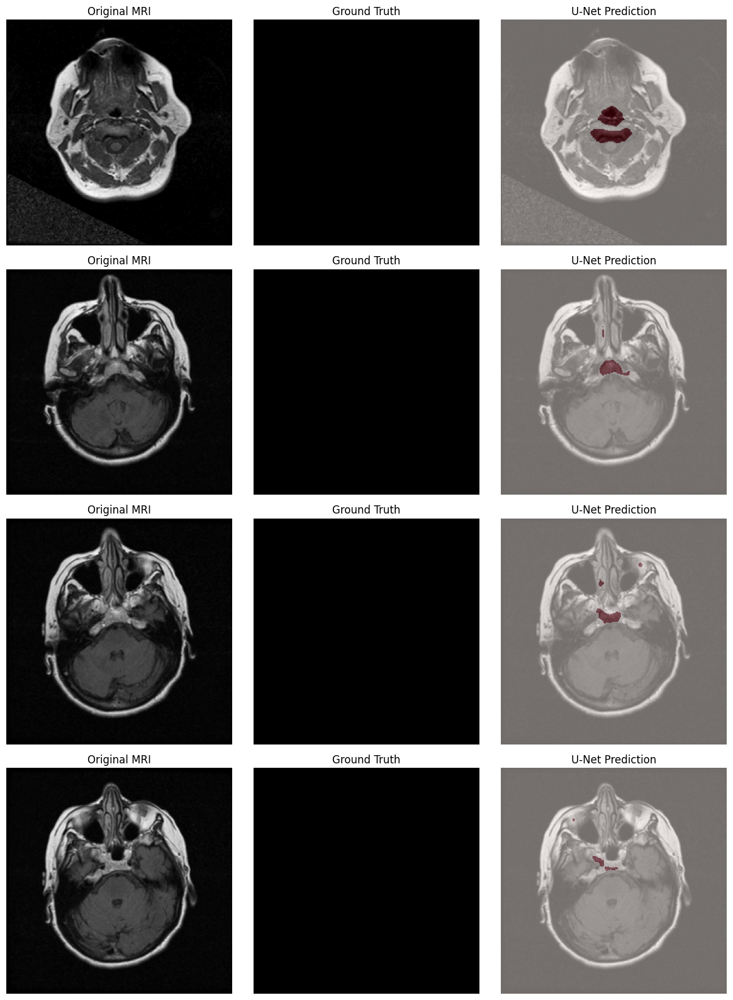

In [ ]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt

checkpoint_path = (
    "/content/drive/MyDrive/BrainTumorSegmentation/"
    "checkpoints/unet_from_scratch_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model = UNet(in_channels=1, out_channels=1).to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Loaded best checkpoint")
print("Best epoch:", checkpoint["epoch"])
print("Best validation Dice:", checkpoint["best_positive_dice"])

images, masks = next(iter(test_loader))
images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    logits = model(images)
    probabilities = torch.sigmoid(logits.float())
    predictions = (probabilities >= 0.5).float()

n = min(4, images.shape[0])

fig, axes = plt.subplots(n, 3, figsize=(12, 4 * n))
if n == 1:
    axes = np.expand_dims(axes, axis=0)

for i in range(n):
    mri = images[i, 0].cpu().numpy()
    mask = masks[i, 0].cpu().numpy()
    pred = predictions[i, 0].cpu().numpy()

    axes[i, 0].imshow(mri, cmap="gray")
    axes[i, 0].set_title("Original MRI")

    axes[i, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Ground Truth")

    axes[i, 2].imshow(mri, cmap="gray")
    axes[i, 2].imshow(pred, cmap="Reds", alpha=0.45, vmin=0, vmax=1)
    axes[i, 2].set_title("U-Net Prediction")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import torch

checkpoint = torch.load(
    "/content/drive/MyDrive/BrainTumorSegmentation/checkpoints/unet_from_scratch_best.pth",
    map_location="cpu",
    weights_only=False
)

print("Checkpoint keys:", checkpoint.keys())

for key, value in checkpoint.items():
    if not isinstance(value, dict):
        print(key, "=", value)

Checkpoint keys: dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_positive_dice', 'config'])
epoch = 3
best_positive_dice = 0.4499432286055847


In [ ]:
import os
import torch
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint_path = (
    "/content/drive/MyDrive/BrainTumorSegmentation/"
    "checkpoints/unet_from_scratch_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model = UNet(in_channels=1, out_channels=1).to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

THRESHOLD = 0.5
records = []

with torch.no_grad():
    for images, masks in tqdm(test_loader, desc="Evaluating test set"):
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        predictions = torch.sigmoid(logits.float()) >= THRESHOLD
        targets = masks >= 0.5

        for i in range(images.size(0)):
            pred = predictions[i, 0]
            target = targets[i, 0]

            intersection = (pred & target).sum().item()
            pred_pixels = pred.sum().item()
            target_pixels = target.sum().item()

            has_tumor = target_pixels > 0

            dice = (
                2 * intersection / (pred_pixels + target_pixels)
                if pred_pixels + target_pixels > 0 else 1.0
            )

            iou = (
                intersection / (pred_pixels + target_pixels - intersection)
                if pred_pixels + target_pixels - intersection > 0 else 1.0
            )

            records.append({
                "has_tumor": has_tumor,
                "dice": dice,
                "iou": iou,
                "predicted_pixels": pred_pixels,
                "true_pixels": target_pixels,
                "intersection": intersection
            })

test_results = pd.DataFrame(records)

positive = test_results[test_results["has_tumor"]]
empty = test_results[~test_results["has_tumor"]]

summary = {
    "Test images": len(test_results),
    "Images with tumor": len(positive),
    "Empty-mask images": len(empty),
    "Mean Dice (positive images)": positive["dice"].mean(),
    "Mean IoU (positive images)": positive["iou"].mean(),
    "Empty-mask False Positive Rate": (
        (empty["predicted_pixels"] > 0).mean() if len(empty) else np.nan
    ),
    "Empty masks with false positives": int(
        (empty["predicted_pixels"] > 0).sum()
    ),
    "Mean predicted tumor area (positive images, pixels)": (
        positive["predicted_pixels"].mean() if len(positive) else np.nan
    )
}

summary_df = pd.DataFrame(
    {"Metric": summary.keys(), "Value": summary.values()}
)

display(summary_df.round(4))

output_path = (
    "/content/drive/MyDrive/BrainTumorSegmentation/"
    "results/unet_from_scratch_test_metrics.csv"
)
test_results.to_csv(output_path, index=False)

print("Saved per-image test results to:", output_path)

Evaluating test set:   0%|          | 0/66 [00:00<?, ?it/s]

,Metric,Value
0,Test images,523.0000
1,Images with tumor,173.0000
2,Empty-mask images,350.0000
3,Mean Dice (positive images),0.3921
4,Mean IoU (positive images),0.2908
5,Empty-mask False Positive Rate,0.8686
6,Empty masks with false positives,304.0000
7,"Mean predicted tumor area (positive images, pi...",3160.5780


Saved per-image test results to: /content/drive/MyDrive/BrainTumorSegmentation/results/unet_from_scratch_test_metrics.csv


In [4]:
import matplotlib.pyplot as plt
import numpy as np
import torch

model.eval()
shown = 0
max_examples = 6

fig, axes = plt.subplots(max_examples, 3, figsize=(12, 4 * max_examples))

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        predictions = (torch.sigmoid(logits.float()) >= 0.5).float()

        for i in range(images.size(0)):
            target = masks[i, 0].cpu().numpy()
            if target.sum() == 0:
                continue

            mri = images[i, 0].cpu().numpy()
            pred = predictions[i, 0].cpu().numpy()

            intersection = (pred * target).sum()
            dice = (2 * intersection + 1e-7) / (
                pred.sum() + target.sum() + 1e-7
            )

            axes[shown, 0].imshow(mri, cmap="gray")
            axes[shown, 0].set_title("Original MRI")

            axes[shown, 1].imshow(mri, cmap="gray")
            axes[shown, 1].imshow(target, cmap="Greens", alpha=0.5)
            axes[shown, 1].set_title("Ground Truth — Green")

            axes[shown, 2].imshow(mri, cmap="gray")
            axes[shown, 2].imshow(target, cmap="Greens", alpha=0.4)
            axes[shown, 2].imshow(pred, cmap="Reds", alpha=0.4)
            axes[shown, 2].set_title(f"Prediction — Red | Dice: {dice:.3f}")

            for ax in axes[shown]:
                ax.axis("off")

            shown += 1
            if shown == max_examples:
                break

        if shown == max_examples:
            break

plt.tight_layout()
plt.show()

print(f"Displayed {shown} positive test images.")

ModuleNotFoundError: No module named 'matplotlib'

In [ ]:
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]
results = []

model.eval()

# Cache validation probabilities once
all_probs = []
all_masks = []

with torch.no_grad():
    for images, masks in tqdm(val_loader, desc="Caching validation predictions"):
        images = images.to(device)
        logits = model(images)

        probs = torch.sigmoid(logits.float()).cpu()
        all_probs.append(probs)
        all_masks.append(masks.cpu())

all_probs = torch.cat(all_probs, dim=0)
all_masks = torch.cat(all_masks, dim=0)

for threshold in thresholds:
    positive_dices = []
    positive_ious = []
    empty_fp = 0
    empty_total = 0

    for i in range(len(all_masks)):
        pred = all_probs[i, 0] >= threshold
        target = all_masks[i, 0] >= 0.5

        intersection = (pred & target).sum().item()
        pred_sum = pred.sum().item()
        target_sum = target.sum().item()

        if target_sum > 0:
            dice = (2 * intersection + 1e-7) / (
                pred_sum + target_sum + 1e-7
            )
            union = pred_sum + target_sum - intersection
            iou = intersection / union if union else 1.0

            positive_dices.append(dice)
            positive_ious.append(iou)
        else:
            empty_total += 1
            if pred_sum > 0:
                empty_fp += 1

    results.append({
        "threshold": threshold,
        "positive_dice": np.mean(positive_dices),
        "positive_iou": np.mean(positive_ious),
        "empty_mask_fpr": empty_fp / empty_total if empty_total else 0
    })

threshold_df = pd.DataFrame(results)
display(threshold_df.round(4))

threshold_df.to_csv(
    "/content/drive/MyDrive/BrainTumorSegmentation/results/"
    "unet_threshold_validation.csv",
    index=False
)

Caching validation predictions:   0%|          | 0/81 [00:00<?, ?it/s]

,threshold,positive_dice,positive_iou,empty_mask_fpr
0,0.2,0.4102,0.2996,0.9000
1,0.3,0.4236,0.3106,0.8773
2,0.4,0.4369,0.3219,0.8614
3,0.5,0.4500,0.3343,0.8250
4,0.6,0.4633,0.3486,0.7932
5,0.7,0.4706,0.3581,0.7295
6,0.8,0.4741,0.3643,0.6614


In [ ]:
import os
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

THRESHOLD = 0.8
model.eval()

test_records = []

with torch.no_grad():
    for images, masks in tqdm(test_loader, desc="Final baseline evaluation"):
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        predictions = torch.sigmoid(logits.float()) >= THRESHOLD
        targets = masks >= 0.5

        for i in range(images.size(0)):
            pred = predictions[i, 0]
            target = targets[i, 0]

            intersection = (pred & target).sum().item()
            pred_pixels = pred.sum().item()
            true_pixels = target.sum().item()
            union = pred_pixels + true_pixels - intersection

            has_tumor = true_pixels > 0

            dice = (
                2 * intersection / (pred_pixels + true_pixels)
                if pred_pixels + true_pixels > 0 else 1.0
            )
            iou = intersection / union if union > 0 else 1.0

            test_records.append({
                "has_tumor": has_tumor,
                "dice": dice,
                "iou": iou,
                "predicted_pixels": pred_pixels,
                "true_pixels": true_pixels
            })

test_df_results = pd.DataFrame(test_records)

positive = test_df_results[test_df_results["has_tumor"]]
empty = test_df_results[~test_df_results["has_tumor"]]

final_metrics = {
    "threshold": THRESHOLD,
    "test_images": len(test_df_results),
    "positive_images": len(positive),
    "empty_images": len(empty),
    "positive_dice": positive["dice"].mean(),
    "positive_iou": positive["iou"].mean(),
    "empty_mask_fpr": (
        (empty["predicted_pixels"] > 0).mean()
        if len(empty) else np.nan
    )
}

display(pd.DataFrame([final_metrics]).round(4))

results_dir = (
    "/content/drive/MyDrive/BrainTumorSegmentation/results"
)
os.makedirs(results_dir, exist_ok=True)

test_df_results.to_csv(
    os.path.join(results_dir, "unet_scratch_test_threshold_08.csv"),
    index=False
)

pd.DataFrame([final_metrics]).to_csv(
    os.path.join(results_dir, "unet_scratch_final_metrics.csv"),
    index=False
)

print("Baseline test metrics saved successfully.")

Final baseline evaluation:   0%|          | 0/66 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fb480349bc0>Exception ignored in: 
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
<function _MultiProcessingDataLoaderIter.__del__ at 0x7fb480349bc0>    
self._shutdown_workers()
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    self._shutdown_workers()if w.is_alive():

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        assert self._parent_pid == os.getpid(), 'can only test a child process'if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 1

,threshold,test_images,positive_images,empty_images,positive_dice,positive_iou,empty_mask_fpr
0,0.8,523,173,350,0.4149,0.3213,0.6886


Baseline test metrics saved successfully.


In [ ]:
!pip -q install segmentation-models-pytorch

In [ ]:
import torch
from torch.utils.data import DataLoader

BATCH_SIZE = 8

train_loader_pretrained = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader_pretrained = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader_pretrained = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Train batches:", len(train_loader_pretrained))
print("Validation batches:", len(val_loader_pretrained))
print("Test batches:", len(test_loader_pretrained))

Train batches: 345
Validation batches: 81
Test batches: 66


In [ ]:
import segmentation_models_pytorch as smp
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

pretrained_model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=1,
    classes=1,
    activation=None
).to(device)

print("Device:", device)
print("Architecture: U-Net + Pretrained ResNet34")
print(
    "Trainable parameters:",
    sum(p.numel() for p in pretrained_model.parameters() if p.requires_grad)
)

images, masks = next(iter(train_loader_pretrained))
images = images.to(device)
masks = masks.to(device)

pretrained_model.eval()

with torch.no_grad():
    logits = pretrained_model(images)
    initial_loss = criterion(logits, masks)

print("Input shape:", images.shape)
print("Output shape:", logits.shape)
print("Initial loss:", round(initial_loss.item(), 4))

assert logits.shape == masks.shape
assert torch.isfinite(initial_loss)

print("Pretrained U-Net checks: PASSED")

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Device: cuda
Architecture: U-Net + Pretrained ResNet34
Trainable parameters: 24430097
Input shape: torch.Size([8, 1, 256, 256])
Output shape: torch.Size([8, 1, 256, 256])
Initial loss: 0.632
Pretrained U-Net checks: PASSED


In [ ]:
import os
import time
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

PROJECT_DIR = "/content/drive/MyDrive/BrainTumorSegmentation"
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

PRETRAINED_PATH = os.path.join(
    CHECKPOINT_DIR, "unet_resnet34_pretrained_best.pth"
)
PRETRAINED_HISTORY_PATH = os.path.join(
    RESULTS_DIR, "unet_resnet34_pretrained_history.csv"
)

EPOCHS = 15
THRESHOLD = 0.5
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

optimizer_pretrained = torch.optim.AdamW(
    pretrained_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler_pretrained = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_pretrained,
    mode="max",
    factor=0.5,
    patience=2
)

amp_enabled = device.type == "cuda"
scaler_pretrained = torch.amp.GradScaler(
    "cuda", enabled=amp_enabled
)

def evaluate_pretrained(loader):
    pretrained_model.eval()

    total_loss = 0.0
    positive_dices = []
    positive_ious = []
    empty_fp = 0
    empty_count = 0

    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device)
            masks = masks.to(device)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=amp_enabled
            ):
                logits = pretrained_model(images)
                loss = criterion(logits, masks)

            total_loss += loss.item() * images.size(0)

            predictions = torch.sigmoid(logits.float()) >= THRESHOLD
            targets = masks >= 0.5

            for i in range(images.size(0)):
                pred = predictions[i, 0]
                target = targets[i, 0]

                intersection = (pred & target).sum().item()
                pred_pixels = pred.sum().item()
                target_pixels = target.sum().item()
                union = pred_pixels + target_pixels - intersection

                if target_pixels > 0:
                    dice = (
                        2 * intersection / (pred_pixels + target_pixels)
                        if pred_pixels + target_pixels > 0 else 1.0
                    )
                    iou = intersection / union if union > 0 else 1.0

                    positive_dices.append(dice)
                    positive_ious.append(iou)
                else:
                    empty_count += 1
                    if pred_pixels > 0:
                        empty_fp += 1

    return {
        "loss": total_loss / len(loader.dataset),
        "positive_dice": float(np.mean(positive_dices)) if positive_dices else 0.0,
        "positive_iou": float(np.mean(positive_ious)) if positive_ious else 0.0,
        "empty_mask_fpr": empty_fp / empty_count if empty_count else 0.0
    }


best_pretrained_dice = -1.0
pretrained_history = []

for epoch in range(1, EPOCHS + 1):
    pretrained_model.train()
    running_loss = 0.0
    start_time = time.time()

    for images, masks in tqdm(
        train_loader_pretrained,
        desc=f"Pretrained Epoch {epoch}/{EPOCHS}"
    ):
        images = images.to(device)
        masks = masks.to(device)

        optimizer_pretrained.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=amp_enabled
        ):
            logits = pretrained_model(images)
            loss = criterion(logits, masks)

        scaler_pretrained.scale(loss).backward()
        scaler_pretrained.step(optimizer_pretrained)
        scaler_pretrained.update()

        running_loss += loss.item() * images.size(0)

    train_loss = running_loss / len(train_loader_pretrained.dataset)
    val_metrics = evaluate_pretrained(val_loader_pretrained)

    scheduler_pretrained.step(val_metrics["positive_dice"])

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_metrics["loss"],
        "val_positive_dice": val_metrics["positive_dice"],
        "val_positive_iou": val_metrics["positive_iou"],
        "val_empty_mask_fpr": val_metrics["empty_mask_fpr"],
        "learning_rate": optimizer_pretrained.param_groups[0]["lr"],
        "epoch_seconds": time.time() - start_time
    }

    pretrained_history.append(record)
    pd.DataFrame(pretrained_history).to_csv(
        PRETRAINED_HISTORY_PATH, index=False
    )

    if val_metrics["positive_dice"] > best_pretrained_dice:
        best_pretrained_dice = val_metrics["positive_dice"]

        torch.save({
            "epoch": epoch,
            "model_state_dict": pretrained_model.state_dict(),
            "optimizer_state_dict": optimizer_pretrained.state_dict(),
            "best_positive_dice": best_pretrained_dice,
            "config": {
                "architecture": "U-Net",
                "encoder": "ResNet34",
                "encoder_weights": "ImageNet",
                "threshold": THRESHOLD,
                "seed": 42
            }
        }, PRETRAINED_PATH)

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Positive Dice: {val_metrics['positive_dice']:.4f} | "
        f"Positive IoU: {val_metrics['positive_iou']:.4f} | "
        f"Empty-mask FPR: {val_metrics['empty_mask_fpr']:.4f} | "
        f"Best Dice: {best_pretrained_dice:.4f}"
    )

print("\nPretrained U-Net training complete.")
print("Best checkpoint:", PRETRAINED_PATH)
print("History:", PRETRAINED_HISTORY_PATH)

Pretrained Epoch 1/15:   0%|          | 0/345 [00:00<?, ?it/s]

Epoch 01 | Train Loss: 0.5433 | Val Loss: 0.4755 | Positive Dice: 0.6166 | Positive IoU: 0.5042 | Empty-mask FPR: 0.4591 | Best Dice: 0.6166


Pretrained Epoch 2/15:   0%|          | 0/345 [00:00<?, ?it/s]

Epoch 02 | Train Loss: 0.4208 | Val Loss: 0.4218 | Positive Dice: 0.6761 | Positive IoU: 0.5728 | Empty-mask FPR: 0.2159 | Best Dice: 0.6761


Pretrained Epoch 3/15:   0%|          | 0/345 [00:00<?, ?it/s]

Epoch 03 | Train Loss: 0.3860 | Val Loss: 0.4105 | Positive Dice: 0.6944 | Positive IoU: 0.5923 | Empty-mask FPR: 0.5341 | Best Dice: 0.6944


... (20 outputs left out)

Pretrained Epoch 14/15:   0%|          | 0/345 [00:00<?, ?it/s]

Epoch 14 | Train Loss: 0.0624 | Val Loss: 0.0787 | Positive Dice: 0.6721 | Positive IoU: 0.5919 | Empty-mask FPR: 0.0455 | Best Dice: 0.7350


Pretrained Epoch 15/15:   0%|          | 0/345 [00:00<?, ?it/s]

Epoch 15 | Train Loss: 0.0638 | Val Loss: 0.0710 | Positive Dice: 0.6785 | Positive IoU: 0.5987 | Empty-mask FPR: 0.0273 | Best Dice: 0.7350

Pretrained U-Net training complete.
Best checkpoint: /content/drive/MyDrive/BrainTumorSegmentation/checkpoints/unet_resnet34_pretrained_best.pth
History: /content/drive/MyDrive/BrainTumorSegmentation/results/unet_resnet34_pretrained_history.csv


In [ ]:
import os
import torch
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
import segmentation_models_pytorch as smp

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint_path = (
    "/content/drive/MyDrive/BrainTumorSegmentation/"
    "checkpoints/unet_resnet34_pretrained_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

pretrained_model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=1,
    classes=1,
    activation=None
).to(device)

pretrained_model.load_state_dict(checkpoint["model_state_dict"])
pretrained_model.eval()

THRESHOLD = 0.5
test_records = []

with torch.no_grad():
    for images, masks in tqdm(
        test_loader_pretrained,
        desc="Evaluating pretrained U-Net"
    ):
        images = images.to(device)
        masks = masks.to(device)

        logits = pretrained_model(images)
        predictions = torch.sigmoid(logits.float()) >= THRESHOLD
        targets = masks >= 0.5

        for i in range(images.size(0)):
            pred = predictions[i, 0]
            target = targets[i, 0]

            intersection = (pred & target).sum().item()
            pred_pixels = pred.sum().item()
            true_pixels = target.sum().item()
            union = pred_pixels + true_pixels - intersection

            test_records.append({
                "has_tumor": true_pixels > 0,
                "dice": (
                    2 * intersection / (pred_pixels + true_pixels)
                    if pred_pixels + true_pixels > 0 else 1.0
                ),
                "iou": intersection / union if union > 0 else 1.0,
                "predicted_pixels": pred_pixels,
                "true_pixels": true_pixels
            })

pretrained_test_df = pd.DataFrame(test_records)

positive = pretrained_test_df[pretrained_test_df["has_tumor"]]
empty = pretrained_test_df[~pretrained_test_df["has_tumor"]]

metrics = {
    "Model": "U-Net + Pretrained ResNet34",
    "Best epoch": checkpoint["epoch"],
    "Threshold": THRESHOLD,
    "Test images": len(pretrained_test_df),
    "Positive Dice": positive["dice"].mean(),
    "Positive IoU": positive["iou"].mean(),
    "Empty-mask FPR": (
        (empty["predicted_pixels"] > 0).mean()
        if len(empty) else np.nan
    )
}

display(pd.DataFrame([metrics]).round(4))

results_dir = (
    "/content/drive/MyDrive/BrainTumorSegmentation/results"
)
os.makedirs(results_dir, exist_ok=True)

pretrained_test_df.to_csv(
    os.path.join(results_dir, "unet_pretrained_test_per_image.csv"),
    index=False
)

pd.DataFrame([metrics]).to_csv(
    os.path.join(results_dir, "unet_pretrained_test_metrics.csv"),
    index=False
)

print("Saved pretrained U-Net test metrics.")

Evaluating pretrained U-Net:   0%|          | 0/66 [00:00<?, ?it/s]

,Model,Best epoch,Threshold,Test images,Positive Dice,Positive IoU,Empty-mask FPR
0,U-Net + Pretrained ResNet34,4,0.5,523,0.7283,0.6221,0.2886


Saved pretrained U-Net test metrics.


In [ ]:
import os
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

# Load the best pretrained checkpoint
checkpoint_path = (
    "/content/drive/MyDrive/BrainTumorSegmentation/"
    "checkpoints/unet_resnet34_pretrained_best.pth"
)

checkpoint = torch.load(
    checkpoint_path, map_location=device, weights_only=False
)

pretrained_model.load_state_dict(checkpoint["model_state_dict"])
pretrained_model.eval()

# Cache validation probabilities once
all_probs = []
all_masks = []

with torch.no_grad():
    for images, masks in tqdm(
        val_loader_pretrained, desc="Caching pretrained validation predictions"
    ):
        images = images.to(device)
        logits = pretrained_model(images)

        all_probs.append(torch.sigmoid(logits.float()).cpu())
        all_masks.append(masks.cpu())

all_probs = torch.cat(all_probs, dim=0)
all_masks = torch.cat(all_masks, dim=0)

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
rows = []

for threshold in thresholds:
    positive_dices = []
    positive_ious = []
    empty_fp = 0
    empty_count = 0

    for i in range(len(all_masks)):
        pred = all_probs[i, 0] >= threshold
        target = all_masks[i, 0] >= 0.5

        intersection = (pred & target).sum().item()
        pred_sum = pred.sum().item()
        target_sum = target.sum().item()
        union = pred_sum + target_sum - intersection

        if target_sum > 0:
            positive_dices.append(
                2 * intersection / (pred_sum + target_sum)
                if pred_sum + target_sum > 0 else 1.0
            )
            positive_ious.append(
                intersection / union if union > 0 else 1.0
            )
        else:
            empty_count += 1
            if pred_sum > 0:
                empty_fp += 1

    rows.append({
        "threshold": threshold,
        "positive_dice": np.mean(positive_dices),
        "positive_iou": np.mean(positive_ious),
        "empty_mask_fpr": empty_fp / empty_count if empty_count else 0.0
    })

threshold_results = pd.DataFrame(rows)
display(threshold_results.round(4))

out_path = (
    "/content/drive/MyDrive/BrainTumorSegmentation/results/"
    "pretrained_unet_threshold_validation.csv"
)
threshold_results.to_csv(out_path, index=False)
print("Saved:", out_path)

Caching pretrained validation predictions:   0%|          | 0/81 [00:00<?, ?it/s]

,threshold,positive_dice,positive_iou,empty_mask_fpr
0,0.3,0.7356,0.6371,0.3364
1,0.4,0.7357,0.6372,0.3205
2,0.5,0.7350,0.6361,0.2977
3,0.6,0.7334,0.6340,0.2864
4,0.7,0.7299,0.6293,0.2682
5,0.8,0.7236,0.6210,0.2341
6,0.9,0.7026,0.5963,0.1955


Saved: /content/drive/MyDrive/BrainTumorSegmentation/results/pretrained_unet_threshold_validation.csv


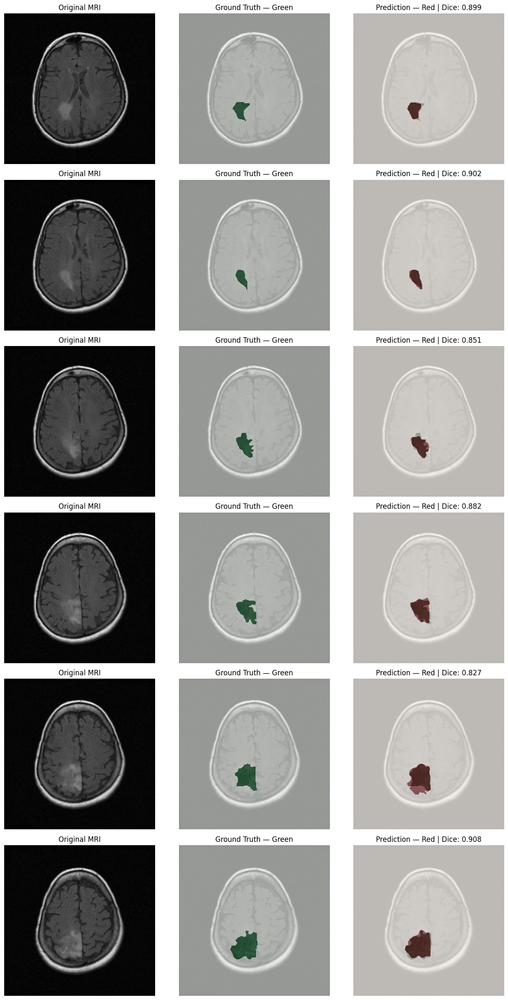

Checkpoint epoch: 4
Visualization threshold: 0.5
Positive test examples displayed: 6


In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load the best pretrained U-Net checkpoint
checkpoint_path = (
    "/content/drive/MyDrive/BrainTumorSegmentation/"
    "checkpoints/unet_resnet34_pretrained_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

pretrained_model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=1,
    classes=1,
    activation=None
).to(device)

pretrained_model.load_state_dict(checkpoint["model_state_dict"])
pretrained_model.eval()

THRESHOLD = 0.5
MAX_IMAGES = 6

# Collect positive test examples and their predictions
examples = []

with torch.no_grad():
    for images, masks in test_loader_pretrained:
        images = images.to(device)
        masks = masks.to(device)

        logits = pretrained_model(images)
        probabilities = torch.sigmoid(logits.float())
        predictions = probabilities >= THRESHOLD

        for i in range(images.size(0)):
            target = masks[i, 0] >= 0.5

            # Show images that actually contain tumor
            if target.any():
                pred = predictions[i, 0]
                intersection = (pred & target).sum().item()
                pred_sum = pred.sum().item()
                target_sum = target.sum().item()

                dice = (
                    2 * intersection / (pred_sum + target_sum)
                    if pred_sum + target_sum > 0 else 1.0
                )

                examples.append((
                    images[i, 0].cpu().numpy(),
                    target.cpu().numpy(),
                    pred.cpu().numpy(),
                    dice
                ))

                if len(examples) == MAX_IMAGES:
                    break

        if len(examples) == MAX_IMAGES:
            break

# Visualize MRI, ground truth and prediction
fig, axes = plt.subplots(
    len(examples), 3,
    figsize=(13, 4 * len(examples))
)

if len(examples) == 1:
    axes = np.expand_dims(axes, axis=0)

for i, (mri, target, pred, dice) in enumerate(examples):
    axes[i, 0].imshow(mri, cmap="gray")
    axes[i, 0].set_title("Original MRI")

    axes[i, 1].imshow(mri, cmap="gray")
    axes[i, 1].imshow(
        target, cmap="Greens", alpha=0.6, vmin=0, vmax=1
    )
    axes[i, 1].set_title("Ground Truth — Green")

    axes[i, 2].imshow(mri, cmap="gray")
    axes[i, 2].imshow(
        target, cmap="Greens", alpha=0.5, vmin=0, vmax=1
    )
    axes[i, 2].imshow(
        pred, cmap="Reds", alpha=0.5, vmin=0, vmax=1
    )
    axes[i, 2].set_title(f"Prediction — Red | Dice: {dice:.3f}")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("Checkpoint epoch:", checkpoint["epoch"])
print("Visualization threshold:", THRESHOLD)
print("Positive test examples displayed:", len(examples))

Checkpoint: /content/drive/MyDrive/BrainTumorSegmentation/checkpoints/unet_resnet34_pretrained_best.pth
Fixed threshold: 0.6
Running final test evaluation...

===== FINAL TEST RESULTS =====
model: Pretrained U-Net (ResNet34)
threshold: 0.6000
test_images: 523
positive_test_images: 173
empty_test_images: 350
positive_dice: 0.7271
positive_iou: 0.6213
empty_mask_fpr: 0.2657

Saved metrics and per-image results to: /content/drive/MyDrive/BrainTumorSegmentation/results


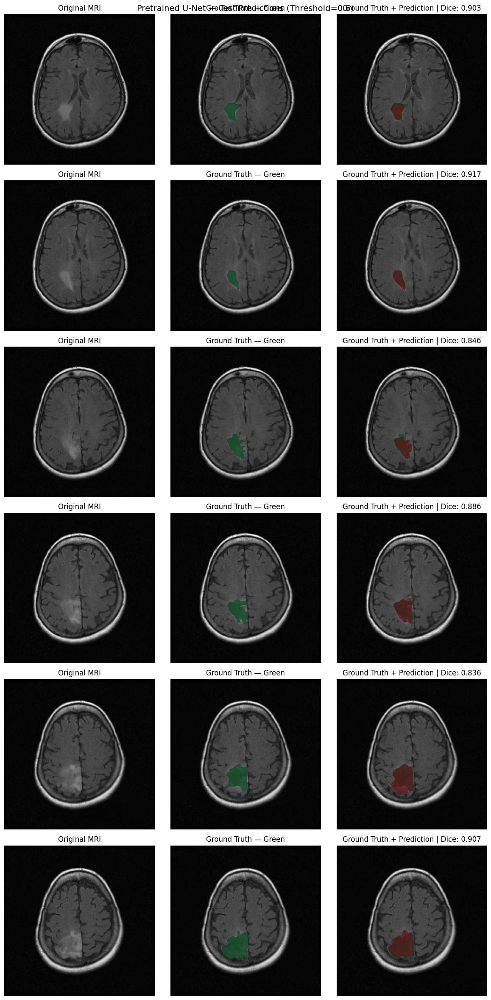

Saved prediction figure: /content/drive/MyDrive/BrainTumorSegmentation/results/figures/pretrained_unet_final_test_predictions.png

===== U-NET COMPARISON =====
                      model  threshold  positive_dice  positive_iou  empty_mask_fpr
         U-Net from scratch        0.8       0.414900      0.321300        0.688600
Pretrained U-Net (ResNet34)        0.6       0.727133      0.621297        0.265714

Saved comparison: /content/drive/MyDrive/BrainTumorSegmentation/results/unet_model_comparison.csv


In [ ]:

# ============================================================
# STEP 2: FINAL TEST EVALUATION — PRETRAINED U-NET
# Threshold selected using Validation Set only: 0.60
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from pathlib import Path

THRESHOLD = 0.60

PROJECT_DIR = "/content/drive/MyDrive/BrainTumorSegmentation"
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
FIGURES_DIR = os.path.join(RESULTS_DIR, "figures")

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR, "unet_resnet34_pretrained_best.pth"
)

# Restore the selected best checkpoint
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
else:
    state_dict = checkpoint

pretrained_model.load_state_dict(state_dict)
pretrained_model.to(device)
pretrained_model.eval()

print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"Fixed threshold: {THRESHOLD}")
print("Running final test evaluation...")

# One inference pass over the test set
all_test_probs = []
all_test_masks = []
all_test_images = []

with torch.inference_mode():
    for images, masks in test_loader_pretrained:
        images = images.to(device)
        masks = masks.to(device)

        logits = pretrained_model(images)
        probs = torch.sigmoid(logits)

        all_test_probs.extend(
            probs.cpu().numpy()[:, 0]
        )
        all_test_masks.extend(
            masks.cpu().numpy()[:, 0]
        )
        all_test_images.extend(
            images.cpu().numpy()[:, 0]
        )

all_test_probs = np.asarray(all_test_probs)
all_test_masks = (np.asarray(all_test_masks) >= 0.5).astype(np.uint8)
all_test_images = np.asarray(all_test_images)

# Metrics
pred_masks = (all_test_probs >= THRESHOLD).astype(np.uint8)

eps = 1e-7
positive_dices = []
positive_ious = []
empty_false_positives = []

per_image_rows = []

for i in range(len(all_test_masks)):
    gt = all_test_masks[i]
    pred = pred_masks[i]

    intersection = np.logical_and(gt, pred).sum()
    union = np.logical_or(gt, pred).sum()
    gt_pixels = gt.sum()
    pred_pixels = pred.sum()

    dice = (2 * intersection + eps) / (
        gt_pixels + pred_pixels + eps
    )
    iou = (intersection + eps) / (union + eps)

    has_tumor = gt_pixels > 0

    if has_tumor:
        positive_dices.append(dice)
        positive_ious.append(iou)
    else:
        empty_false_positives.append(float(pred_pixels > 0))

    per_image_rows.append({
        "test_index": i,
        "has_tumor": bool(has_tumor),
        "ground_truth_pixels": int(gt_pixels),
        "predicted_pixels": int(pred_pixels),
        "dice": float(dice),
        "iou": float(iou),
        "false_positive_on_empty": (
            int(pred_pixels > 0) if not has_tumor else np.nan
        ),
        "threshold": THRESHOLD
    })

positive_dice = float(np.mean(positive_dices)) if positive_dices else 0.0
positive_iou = float(np.mean(positive_ious)) if positive_ious else 0.0
empty_fpr = float(np.mean(empty_false_positives)) if empty_false_positives else 0.0

metrics = {
    "model": "Pretrained U-Net (ResNet34)",
    "threshold": THRESHOLD,
    "test_images": len(all_test_masks),
    "positive_test_images": len(positive_dices),
    "empty_test_images": len(empty_false_positives),
    "positive_dice": positive_dice,
    "positive_iou": positive_iou,
    "empty_mask_fpr": empty_fpr,
}

metrics_df = pd.DataFrame([metrics])
per_image_df = pd.DataFrame(per_image_rows)

metrics_df.to_csv(
    os.path.join(RESULTS_DIR, "pretrained_unet_final_test_metrics.csv"),
    index=False
)
per_image_df.to_csv(
    os.path.join(RESULTS_DIR, "pretrained_unet_final_test_per_image.csv"),
    index=False
)

print("\n===== FINAL TEST RESULTS =====")
for key, value in metrics.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

print("\nSaved metrics and per-image results to:", RESULTS_DIR)

# ============================================================
# STEP 3: SAVE VISUAL PREDICTIONS FROM THE SAME TEST INFERENCE
# Green = ground truth; Red = prediction; overlap = mixed color
# ============================================================

positive_indices = [
    i for i, mask in enumerate(all_test_masks)
    if mask.sum() > 0
][:6]

if positive_indices:
    n = len(positive_indices)
    fig, axes = plt.subplots(n, 3, figsize=(12, 4 * n))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, idx in enumerate(positive_indices):
        image = all_test_images[idx]
        gt = all_test_masks[idx]
        pred = pred_masks[idx]
        dice = per_image_rows[idx]["dice"]

        axes[row, 0].imshow(image, cmap="gray")
        axes[row, 0].set_title("Original MRI")

        axes[row, 1].imshow(image, cmap="gray")
        axes[row, 1].imshow(
            np.ma.masked_where(gt == 0, gt),
            cmap="Greens", alpha=0.7, vmin=0, vmax=1
        )
        axes[row, 1].set_title("Ground Truth — Green")

        axes[row, 2].imshow(image, cmap="gray")
        axes[row, 2].imshow(
            np.ma.masked_where(gt == 0, gt),
            cmap="Greens", alpha=0.65, vmin=0, vmax=1
        )
        axes[row, 2].imshow(
            np.ma.masked_where(pred == 0, pred),
            cmap="Reds", alpha=0.55, vmin=0, vmax=1
        )
        axes[row, 2].set_title(
            f"Ground Truth + Prediction | Dice: {dice:.3f}"
        )

        for ax in axes[row]:
            ax.axis("off")

    plt.suptitle(
        f"Pretrained U-Net — Test Predictions (Threshold={THRESHOLD})",
        fontsize=14
    )
    plt.tight_layout()

    figure_path = os.path.join(
        FIGURES_DIR, "pretrained_unet_final_test_predictions.png"
    )
    plt.savefig(figure_path, dpi=180, bbox_inches="tight")
    plt.show()
    print("Saved prediction figure:", figure_path)
else:
    print("No positive-mask examples found in the test set.")

# ============================================================
# STEP 4: SAVE COMPARISON WITH FROM-SCRATCH U-NET
# Baseline values are the previously recorded test results.
# ============================================================

comparison_df = pd.DataFrame([
    {
        "model": "U-Net from scratch",
        "threshold": 0.8,
        "positive_dice": 0.4149,
        "positive_iou": 0.3213,
        "empty_mask_fpr": 0.6886
    },
    {
        "model": "Pretrained U-Net (ResNet34)",
        "threshold": THRESHOLD,
        "positive_dice": positive_dice,
        "positive_iou": positive_iou,
        "empty_mask_fpr": empty_fpr
    }
])

comparison_path = os.path.join(
    RESULTS_DIR, "unet_model_comparison.csv"
)
comparison_df.to_csv(comparison_path, index=False)

print("\n===== U-NET COMPARISON =====")
print(comparison_df.to_string(index=False))
print("\nSaved comparison:", comparison_path)


In [ ]:

!pip -q install -U transformers

import os
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import SegformerForSemanticSegmentation
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

PROJECT_DIR = "/content/drive/MyDrive/BrainTumorSegmentation"
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# Wrap the existing datasets; no new split and no patient leakage.
class SegFormerDataset(Dataset):
    def __init__(self, base_dataset):
        self.base_dataset = base_dataset

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        image, mask = self.base_dataset[idx]

        # Grayscale [1,H,W] -> 3 channels for pretrained encoder.
        image = image.float()
        if image.ndim == 2:
            image = image.unsqueeze(0)
        if image.shape[0] == 1:
            image = image.repeat(3, 1, 1)
        elif image.shape[0] != 3:
            raise ValueError(f"Unexpected image shape: {image.shape}")

        # ImageNet normalization for the pretrained encoder.
        mean = torch.tensor(
            [0.485, 0.456, 0.406], dtype=image.dtype
        ).view(3, 1, 1)
        std = torch.tensor(
            [0.229, 0.224, 0.225], dtype=image.dtype
        ).view(3, 1, 1)
        image = (image - mean) / std

        mask = mask.float()
        if mask.ndim == 2:
            mask = mask.unsqueeze(0)
        mask = (mask >= 0.5).float()

        return image, mask

train_dataset_seg = SegFormerDataset(train_dataset)
val_dataset_seg = SegFormerDataset(val_dataset)
test_dataset_seg = SegFormerDataset(test_dataset)

BATCH_SIZE_SEG = 8

train_loader_seg = DataLoader(
    train_dataset_seg, batch_size=BATCH_SIZE_SEG,
    shuffle=True, num_workers=0, pin_memory=torch.cuda.is_available()
)
val_loader_seg = DataLoader(
    val_dataset_seg, batch_size=BATCH_SIZE_SEG,
    shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available()
)
test_loader_seg = DataLoader(
    test_dataset_seg, batch_size=BATCH_SIZE_SEG,
    shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available()
)

x, y = next(iter(train_loader_seg))
print("Image batch:", x.shape, x.dtype)
print("Mask batch:", y.shape, y.dtype)
print("Mask values:", torch.unique(y))


Device: cuda
Image batch: torch.Size([8, 3, 256, 256]) torch.float32
Mask batch: torch.Size([8, 1, 256, 256]) torch.float32
Mask values: tensor([0., 1.])


In [ ]:

MODEL_NAME = "nvidia/segformer-b0-finetuned-ade-512-512"

segformer_model = SegformerForSemanticSegmentation.from_pretrained(
    MODEL_NAME,
    num_labels=1,
    ignore_mismatched_sizes=True
).to(device)

print("SegFormer-B0 loaded.")
print(
    "Trainable parameters:",
    sum(p.numel() for p in segformer_model.parameters() if p.requires_grad)
)


config.json:   0%|          | 0.00/6.88k [00:00<?, ?B/s]

[transformers] You passed `num_labels=1` which is incompatible to the `id2label` map of length `150`.


model.safetensors: reconstructing file:   0%|          |  0.00B / 15.0MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([1, 256, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([1])                      

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


SegFormer-B0 loaded.
Trainable parameters: 3714401


In [ ]:

def segformer_loss(logits, masks):
    # SegFormer outputs lower-resolution logits; resize to mask resolution.
    logits = F.interpolate(
        logits, size=masks.shape[-2:],
        mode="bilinear", align_corners=False
    )

    bce = F.binary_cross_entropy_with_logits(logits, masks)

    probs = torch.sigmoid(logits)
    dims = (1, 2, 3)
    intersection = (probs * masks).sum(dims)
    denominator = probs.sum(dims) + masks.sum(dims)
    dice = (2 * intersection + 1.0) / (denominator + 1.0)
    dice_loss = 1.0 - dice.mean()

    return 0.5 * bce + 0.5 * dice_loss


@torch.inference_mode()
def evaluate_segformer(model, loader, threshold=0.5):
    model.eval()
    positive_dices, positive_ious = [], []
    empty_false_positives = []

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)

        logits = model(pixel_values=images).logits
        logits = F.interpolate(
            logits, size=masks.shape[-2:],
            mode="bilinear", align_corners=False
        )
        probs = torch.sigmoid(logits)
        preds = probs >= threshold
        gts = masks >= 0.5

        for pred, gt in zip(preds, gts):
            pred = pred[0]
            gt = gt[0]

            intersection = (pred & gt).sum().item()
            pred_pixels = pred.sum().item()
            gt_pixels = gt.sum().item()
            union = (pred | gt).sum().item()

            if gt_pixels > 0:
                positive_dices.append(
                    (2 * intersection + 1e-7) /
                    (pred_pixels + gt_pixels + 1e-7)
                )
                positive_ious.append(
                    (intersection + 1e-7) / (union + 1e-7)
                )
            else:
                empty_false_positives.append(
                    float(pred_pixels > 0)
                )

    return {
        "positive_dice": float(np.mean(positive_dices)) if positive_dices else 0.0,
        "positive_iou": float(np.mean(positive_ious)) if positive_ious else 0.0,
        "empty_mask_fpr": float(np.mean(empty_false_positives)) if empty_false_positives else 0.0
    }


In [ ]:

EPOCHS_SEG = 10
LR_SEG = 6e-5
WEIGHT_DECAY_SEG = 1e-4

optimizer_seg = torch.optim.AdamW(
    segformer_model.parameters(),
    lr=LR_SEG,
    weight_decay=WEIGHT_DECAY_SEG
)

use_amp = device.type == "cuda"
scaler_seg = torch.amp.GradScaler("cuda", enabled=use_amp)

BEST_SEG_PATH = os.path.join(
    CHECKPOINT_DIR, "segformer_b0_best.pth"
)
best_val_dice = -1.0
history_seg = []

for epoch in range(1, EPOCHS_SEG + 1):
    segformer_model.train()
    train_losses = []

    loop = tqdm(train_loader_seg, desc=f"SegFormer Epoch {epoch}/{EPOCHS_SEG}")

    for images, masks in loop:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer_seg.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=use_amp
        ):
            logits = segformer_model(pixel_values=images).logits
            loss = segformer_loss(logits, masks)

        scaler_seg.scale(loss).backward()
        scaler_seg.step(optimizer_seg)
        scaler_seg.update()

        train_losses.append(loss.item())
        loop.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = float(np.mean(train_losses))
    val_metrics = evaluate_segformer(
        segformer_model, val_loader_seg, threshold=0.5
    )

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        **{f"val_{k}": v for k, v in val_metrics.items()}
    }
    history_seg.append(row)

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Positive Dice: {val_metrics['positive_dice']:.4f} | "
        f"Val IoU: {val_metrics['positive_iou']:.4f} | "
        f"Empty-mask FPR: {val_metrics['empty_mask_fpr']:.4f}"
    )

    if val_metrics["positive_dice"] > best_val_dice:
        best_val_dice = val_metrics["positive_dice"]
        torch.save({
            "epoch": epoch,
            "model_state_dict": segformer_model.state_dict(),
            "optimizer_state_dict": optimizer_seg.state_dict(),
            "best_val_positive_dice": best_val_dice,
            "model_name": MODEL_NAME
        }, BEST_SEG_PATH)
        print("  Saved new best checkpoint.")

history_seg_df = pd.DataFrame(history_seg)
history_seg_df.to_csv(
    os.path.join(RESULTS_DIR, "segformer_training_history.csv"),
    index=False
)

print("\nBest validation Dice:", round(best_val_dice, 4))
print("Best checkpoint:", BEST_SEG_PATH)


SegFormer Epoch 1/10:   0%|          | 0/345 [00:00<?, ?it/s]

Epoch 01 | Train Loss: 0.6435 | Val Positive Dice: 0.4762 | Val IoU: 0.3552 | Empty-mask FPR: 0.1227
  Saved new best checkpoint.


SegFormer Epoch 2/10:   0%|          | 0/345 [00:00<?, ?it/s]

Epoch 02 | Train Loss: 0.4775 | Val Positive Dice: 0.6146 | Val IoU: 0.4919 | Empty-mask FPR: 0.1636
  Saved new best checkpoint.


SegFormer Epoch 3/10:   0%|          | 0/345 [00:00<?, ?it/s]

Epoch 03 | Train Loss: 0.4214 | Val Positive Dice: 0.6486 | Val IoU: 0.5381 | Empty-mask FPR: 0.1318
  Saved new best checkpoint.


... (10 outputs left out)

SegFormer Epoch 9/10:   0%|          | 0/345 [00:00<?, ?it/s]

Epoch 09 | Train Loss: 0.3071 | Val Positive Dice: 0.5459 | Val IoU: 0.4461 | Empty-mask FPR: 0.1114


SegFormer Epoch 10/10:   0%|          | 0/345 [00:00<?, ?it/s]

Epoch 10 | Train Loss: 0.1596 | Val Positive Dice: 0.4842 | Val IoU: 0.3699 | Empty-mask FPR: 0.2182

Best validation Dice: 0.7072
Best checkpoint: /content/drive/MyDrive/BrainTumorSegmentation/checkpoints/segformer_b0_best.pth


In [ ]:

# ============================================================
# STEP 5: SEGFORMER THRESHOLD TUNING — VALIDATION ONLY
# ============================================================

import os
import torch
import numpy as np
import pandas as pd
import torch.nn.functional as F
from tqdm.auto import tqdm

BEST_SEG_PATH = (
    "/content/drive/MyDrive/BrainTumorSegmentation/"
    "checkpoints/segformer_b0_best.pth"
)

checkpoint = torch.load(BEST_SEG_PATH, map_location=device)
segformer_model.load_state_dict(checkpoint["model_state_dict"])
segformer_model.to(device)
segformer_model.eval()

print("Restored best epoch:", checkpoint["epoch"])
print("Best validation Dice at threshold 0.5:",
      checkpoint["best_val_positive_dice"])

# Cache validation probabilities once.
val_probs_seg = []
val_masks_seg = []

with torch.inference_mode():
    for images, masks in tqdm(val_loader_seg, desc="Validation inference"):
        images = images.to(device)
        masks = masks.to(device)

        logits = segformer_model(pixel_values=images).logits
        logits = F.interpolate(
            logits,
            size=masks.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        val_probs_seg.append(torch.sigmoid(logits).cpu().numpy()[:, 0])
        val_masks_seg.append(masks.cpu().numpy()[:, 0])

val_probs_seg = np.concatenate(val_probs_seg, axis=0)
val_masks_seg = (np.concatenate(val_masks_seg, axis=0) >= 0.5).astype(np.uint8)

def calculate_seg_metrics(probs, masks, threshold):
    preds = probs >= threshold
    positive_dices, positive_ious = [], []
    empty_fps = []

    for pred, gt in zip(preds, masks):
        intersection = np.logical_and(pred, gt).sum()
        union = np.logical_or(pred, gt).sum()
        pred_pixels = pred.sum()
        gt_pixels = gt.sum()

        if gt_pixels > 0:
            dice = (2 * intersection + 1e-7) / (
                pred_pixels + gt_pixels + 1e-7
            )
            iou = (intersection + 1e-7) / (union + 1e-7)
            positive_dices.append(dice)
            positive_ious.append(iou)
        else:
            empty_fps.append(float(pred_pixels > 0))

    return {
        "threshold": threshold,
        "positive_dice": float(np.mean(positive_dices)),
        "positive_iou": float(np.mean(positive_ious)),
        "empty_mask_fpr": float(np.mean(empty_fps)) if empty_fps else 0.0
    }

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

threshold_results_seg = pd.DataFrame([
    calculate_seg_metrics(val_probs_seg, val_masks_seg, t)
    for t in thresholds
])

print("\nValidation threshold results:")
print(threshold_results_seg.round(4).to_string(index=False))

threshold_csv = os.path.join(
    "/content/drive/MyDrive/BrainTumorSegmentation/results",
    "segformer_validation_threshold_tuning.csv"
)
threshold_results_seg.to_csv(threshold_csv, index=False)
print("\nSaved:", threshold_csv)


Restored best epoch: 6
Best validation Dice at threshold 0.5: 0.7071642793120584


Validation inference:   0%|          | 0/81 [00:00<?, ?it/s]


Validation threshold results:
 threshold  positive_dice  positive_iou  empty_mask_fpr
       0.3         0.7201        0.6163          0.3295
       0.4         0.7131        0.6111          0.2727
       0.5         0.7072        0.6058          0.1932
       0.6         0.6967        0.5966          0.1659
       0.7         0.6860        0.5862          0.1318
       0.8         0.6720        0.5720          0.0932
       0.9         0.6465        0.5442          0.0705

Saved: /content/drive/MyDrive/BrainTumorSegmentation/results/segformer_validation_threshold_tuning.csv


Best checkpoint epoch: 6
Fixed threshold: 0.5
Starting one final test inference pass...


Final SegFormer test:   0%|          | 0/66 [00:00<?, ?it/s]


===== SEGFORMER FINAL TEST RESULTS =====
model: SegFormer-B0
checkpoint_epoch: 6
threshold: 0.5000
test_images: 523
positive_test_images: 173
empty_test_images: 350
positive_dice: 0.7205
positive_iou: 0.6081
empty_mask_fpr: 0.2057


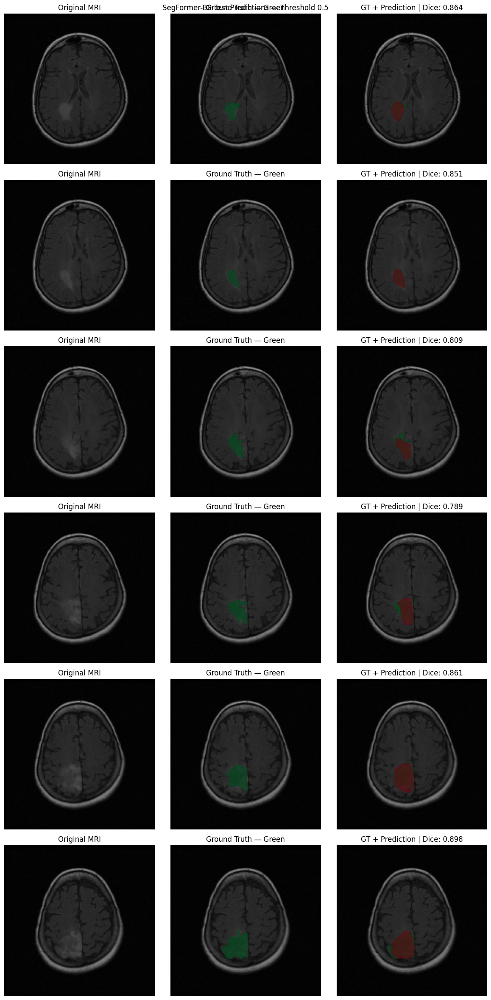

Saved visualizations: /content/drive/MyDrive/BrainTumorSegmentation/results/figures/segformer_final_test_predictions.png

===== FINAL MODEL COMPARISON =====
                      model  threshold  positive_dice  positive_iou  empty_mask_fpr
         U-Net from scratch        0.8         0.4149        0.3213          0.6886
Pretrained U-Net (ResNet34)        0.6         0.7271        0.6213          0.2657
               SegFormer-B0        0.5         0.7205        0.6081          0.2057

Saved comparison: /content/drive/MyDrive/BrainTumorSegmentation/results/final_model_comparison.csv


In [ ]:

# ============================================================
# FINAL TEST EVALUATION — SEGFORMER-B0
# Threshold selected on Validation Set only: 0.50
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

THRESHOLD_SEG_FINAL = 0.50

PROJECT_DIR = "/content/drive/MyDrive/BrainTumorSegmentation"
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
FIGURES_DIR = os.path.join(RESULTS_DIR, "figures")

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

# Restore best validation checkpoint
checkpoint = torch.load(
    os.path.join(CHECKPOINT_DIR, "segformer_b0_best.pth"),
    map_location=device
)
segformer_model.load_state_dict(checkpoint["model_state_dict"])
segformer_model.to(device)
segformer_model.eval()

print("Best checkpoint epoch:", checkpoint["epoch"])
print("Fixed threshold:", THRESHOLD_SEG_FINAL)
print("Starting one final test inference pass...")

test_probs_seg = []
test_masks_seg = []
test_images_display_seg = []

# One pass through test data; cache outputs for metrics and visualizations.
with torch.inference_mode():
    for images, masks in tqdm(test_loader_seg, desc="Final SegFormer test"):
        images = images.to(device)
        masks = masks.to(device)

        logits = segformer_model(pixel_values=images).logits
        logits = F.interpolate(
            logits,
            size=masks.shape[-2:],
            mode="bilinear",
            align_corners=False
        )
        probs = torch.sigmoid(logits)

        test_probs_seg.extend(probs.cpu().numpy()[:, 0])
        test_masks_seg.extend(masks.cpu().numpy()[:, 0])

        # Undo ImageNet normalization for display only.
        display_images = images.cpu().clone()
        mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        display_images = display_images * std + mean
        display_images = display_images.mean(dim=1).numpy()
        test_images_display_seg.extend(display_images)

test_probs_seg = np.asarray(test_probs_seg)
test_masks_seg = (np.asarray(test_masks_seg) >= 0.5).astype(np.uint8)
test_images_display_seg = np.asarray(test_images_display_seg)

test_preds_seg = (test_probs_seg >= THRESHOLD_SEG_FINAL).astype(np.uint8)

positive_dices_seg, positive_ious_seg, empty_fps_seg = [], [], []
per_image_rows_seg = []

for i, (gt, pred) in enumerate(zip(test_masks_seg, test_preds_seg)):
    intersection = np.logical_and(gt, pred).sum()
    union = np.logical_or(gt, pred).sum()
    gt_pixels = int(gt.sum())
    pred_pixels = int(pred.sum())

    dice = (2 * intersection + 1e-7) / (
        gt_pixels + pred_pixels + 1e-7
    )
    iou = (intersection + 1e-7) / (union + 1e-7)
    has_tumor = gt_pixels > 0

    if has_tumor:
        positive_dices_seg.append(dice)
        positive_ious_seg.append(iou)
    else:
        empty_fps_seg.append(float(pred_pixels > 0))

    per_image_rows_seg.append({
        "test_index": i,
        "has_tumor": bool(has_tumor),
        "ground_truth_pixels": gt_pixels,
        "predicted_pixels": pred_pixels,
        "dice": float(dice),
        "iou": float(iou),
        "false_positive_on_empty": (
            int(pred_pixels > 0) if not has_tumor else np.nan
        ),
        "threshold": THRESHOLD_SEG_FINAL
    })

seg_dice_test = float(np.mean(positive_dices_seg))
seg_iou_test = float(np.mean(positive_ious_seg))
seg_empty_fpr_test = (
    float(np.mean(empty_fps_seg)) if empty_fps_seg else 0.0
)

seg_metrics = {
    "model": "SegFormer-B0",
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "threshold": THRESHOLD_SEG_FINAL,
    "test_images": len(test_masks_seg),
    "positive_test_images": len(positive_dices_seg),
    "empty_test_images": len(empty_fps_seg),
    "positive_dice": seg_dice_test,
    "positive_iou": seg_iou_test,
    "empty_mask_fpr": seg_empty_fpr_test
}

pd.DataFrame([seg_metrics]).to_csv(
    os.path.join(RESULTS_DIR, "segformer_final_test_metrics.csv"),
    index=False
)
pd.DataFrame(per_image_rows_seg).to_csv(
    os.path.join(RESULTS_DIR, "segformer_final_test_per_image.csv"),
    index=False
)

print("\n===== SEGFORMER FINAL TEST RESULTS =====")
for key, value in seg_metrics.items():
    print(f"{key}: {value:.4f}" if isinstance(value, float) else f"{key}: {value}")

# Save visual comparison for six positive-mask test images.
positive_indices_seg = [
    i for i, mask in enumerate(test_masks_seg) if mask.sum() > 0
][:6]

if positive_indices_seg:
    n = len(positive_indices_seg)
    fig, axes = plt.subplots(n, 3, figsize=(12, 4 * n))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, idx in enumerate(positive_indices_seg):
        img = test_images_display_seg[idx]
        gt = test_masks_seg[idx]
        pred = test_preds_seg[idx]
        dice = per_image_rows_seg[idx]["dice"]

        axes[row, 0].imshow(img, cmap="gray", vmin=0, vmax=1)
        axes[row, 0].set_title("Original MRI")

        axes[row, 1].imshow(img, cmap="gray", vmin=0, vmax=1)
        axes[row, 1].imshow(
            np.ma.masked_where(gt == 0, gt),
            cmap="Greens", alpha=0.7, vmin=0, vmax=1
        )
        axes[row, 1].set_title("Ground Truth — Green")

        axes[row, 2].imshow(img, cmap="gray", vmin=0, vmax=1)
        axes[row, 2].imshow(
            np.ma.masked_where(gt == 0, gt),
            cmap="Greens", alpha=0.65, vmin=0, vmax=1
        )
        axes[row, 2].imshow(
            np.ma.masked_where(pred == 0, pred),
            cmap="Reds", alpha=0.55, vmin=0, vmax=1
        )
        axes[row, 2].set_title(f"GT + Prediction | Dice: {dice:.3f}")

        for ax in axes[row]:
            ax.axis("off")

    plt.suptitle(
        f"SegFormer-B0 Test Predictions — Threshold {THRESHOLD_SEG_FINAL}"
    )
    plt.tight_layout()

    seg_fig_path = os.path.join(
        FIGURES_DIR, "segformer_final_test_predictions.png"
    )
    plt.savefig(seg_fig_path, dpi=180, bbox_inches="tight")
    plt.show()
    print("Saved visualizations:", seg_fig_path)

# Combine the previously recorded U-Net test results with SegFormer.
comparison_df = pd.DataFrame([
    {
        "model": "U-Net from scratch",
        "threshold": 0.8,
        "positive_dice": 0.4149,
        "positive_iou": 0.3213,
        "empty_mask_fpr": 0.6886
    },
    {
        "model": "Pretrained U-Net (ResNet34)",
        "threshold": 0.6,
        "positive_dice": 0.727133,
        "positive_iou": 0.621297,
        "empty_mask_fpr": 0.265714
    },
    {
        "model": "SegFormer-B0",
        "threshold": THRESHOLD_SEG_FINAL,
        "positive_dice": seg_dice_test,
        "positive_iou": seg_iou_test,
        "empty_mask_fpr": seg_empty_fpr_test
    }
])

comparison_path = os.path.join(RESULTS_DIR, "final_model_comparison.csv")
comparison_df.to_csv(comparison_path, index=False)

print("\n===== FINAL MODEL COMPARISON =====")
print(comparison_df.round(4).to_string(index=False))
print("\nSaved comparison:", comparison_path)


In [ ]:

# ============================================================
# FINAL AUDIT 1 — PATIENT SPLIT + METRIC CONSISTENCY
# ============================================================

import os
import glob
import numpy as np
import pandas as pd

PROJECT_DIR = "/content/drive/MyDrive/BrainTumorSegmentation"
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
AUDIT_DIR = os.path.join(RESULTS_DIR, "final_audit")
os.makedirs(AUDIT_DIR, exist_ok=True)

# 1. Verify patient-level separation
required_dfs = ["train_df", "val_df", "test_df"]
for name in required_dfs:
    assert name in globals(), (
        f"{name} is missing. Re-run the data-splitting cells first."
    )

def get_patients(df):
    assert "patient" in df.columns, "Expected a 'patient' column."
    return set(df["patient"].dropna().astype(str).unique())

train_patients = get_patients(train_df)
val_patients = get_patients(val_df)
test_patients = get_patients(test_df)

overlap_train_val = train_patients & val_patients
overlap_train_test = train_patients & test_patients
overlap_val_test = val_patients & test_patients

split_audit = pd.DataFrame([
    {"check": "Train vs Validation patient overlap",
     "overlap_count": len(overlap_train_val),
     "status": "PASS" if not overlap_train_val else "FAIL"},
    {"check": "Train vs Test patient overlap",
     "overlap_count": len(overlap_train_test),
     "status": "PASS" if not overlap_train_test else "FAIL"},
    {"check": "Validation vs Test patient overlap",
     "overlap_count": len(overlap_val_test),
     "status": "PASS" if not overlap_val_test else "FAIL"},
])

print("===== PATIENT SPLIT AUDIT =====")
print(f"Train: {len(train_df)} images, {len(train_patients)} patients")
print(f"Validation: {len(val_df)} images, {len(val_patients)} patients")
print(f"Test: {len(test_df)} images, {len(test_patients)} patients")
print(split_audit.to_string(index=False))

split_audit.to_csv(
    os.path.join(AUDIT_DIR, "patient_split_audit.csv"), index=False
)

assert not (overlap_train_val or overlap_train_test or overlap_val_test), (
    "Patient leakage detected. Stop before finalizing results."
)

# 2. Locate the saved metrics files
print("\n===== METRICS FILES FOUND =====")
for path in sorted(glob.glob(os.path.join(RESULTS_DIR, "**", "*.csv"),
                             recursive=True)):
    if any(term in os.path.basename(path).lower()
           for term in ["metrics", "comparison", "per_image"]):
        print(os.path.relpath(path, RESULTS_DIR))

# 3. Check metric consistency from per-image CSVs where available.
# Positive Dice/IoU are averaged over GT-positive images only.
# Empty-mask FPR is the fraction of GT-empty images with any predicted pixels.
per_image_files = glob.glob(
    os.path.join(RESULTS_DIR, "**", "*per_image*.csv"),
    recursive=True
)

audit_rows = []

for path in sorted(per_image_files):
    df = pd.read_csv(path)

    needed = {
        "has_tumor", "dice", "iou",
        "false_positive_on_empty", "threshold"
    }
    if not needed.issubset(df.columns):
        continue

    positive = df[df["has_tumor"].astype(bool)]
    empty = df[~df["has_tumor"].astype(bool)]

    recalculated = {
        "file": os.path.basename(path),
        "n_images": len(df),
        "positive_images": len(positive),
        "empty_images": len(empty),
        "recalc_positive_dice": positive["dice"].mean(),
        "recalc_positive_iou": positive["iou"].mean(),
        "recalc_empty_mask_fpr": empty[
            "false_positive_on_empty"
        ].mean(),
        "thresholds_used": ",".join(
            map(str, sorted(df["threshold"].dropna().unique()))
        )
    }
    audit_rows.append(recalculated)

if audit_rows:
    metric_audit_df = pd.DataFrame(audit_rows)
    print("\n===== METRICS RECOMPUTED FROM PER-IMAGE FILES =====")
    print(metric_audit_df.round(5).to_string(index=False))
    metric_audit_df.to_csv(
        os.path.join(AUDIT_DIR, "metric_definition_audit.csv"),
        index=False
    )
else:
    print(
        "\nNo compatible per-image CSVs found. "
        "Check the filenames and column names printed above."
    )

print("\nAudit files saved to:", AUDIT_DIR)


===== PATIENT SPLIT AUDIT =====
Train: 2760 images, 77 patients
Validation: 646 images, 16 patients
Test: 523 images, 17 patients
                              check  overlap_count status
Train vs Validation patient overlap              0   PASS
      Train vs Test patient overlap              0   PASS
 Validation vs Test patient overlap              0   PASS

===== METRICS FILES FOUND =====
final_model_comparison.csv
pretrained_unet_final_test_metrics.csv
pretrained_unet_final_test_per_image.csv
segformer_final_test_metrics.csv
segformer_final_test_per_image.csv
unet_from_scratch_test_metrics.csv
unet_model_comparison.csv
unet_pretrained_test_metrics.csv
unet_pretrained_test_per_image.csv
unet_scratch_final_metrics.csv

===== METRICS RECOMPUTED FROM PER-IMAGE FILES =====
                                    file  n_images  positive_images  empty_images  recalc_positive_dice  recalc_positive_iou  recalc_empty_mask_fpr thresholds_used
pretrained_unet_final_test_per_image.csv       523   

In [ ]:

# ============================================================
# EXPORT BEST MODEL — PRETRAINED U-NET (RESNET34)
# Save to Google Drive and download to your computer
# ============================================================

import os
import json
import torch
import pandas as pd
from google.colab import files

PROJECT_DIR = "/content/drive/MyDrive/BrainTumorSegmentation"
CHECKPOINT_PATH = os.path.join(
    PROJECT_DIR, "checkpoints", "unet_resnet34_pretrained_best.pth"
)

EXPORT_DIR = os.path.join(PROJECT_DIR, "exported_model")
os.makedirs(EXPORT_DIR, exist_ok=True)

EXPORT_PATH = os.path.join(
    EXPORT_DIR, "brain_tumor_pretrained_unet_resnet34.pth"
)
CONFIG_PATH = os.path.join(EXPORT_DIR, "model_config.json")

assert os.path.exists(CHECKPOINT_PATH), (
    f"Checkpoint not found: {CHECKPOINT_PATH}"
)

# Load the best saved checkpoint.
checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu")

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
    best_epoch = checkpoint.get("epoch", None)
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
    best_epoch = checkpoint.get("epoch", None)
else:
    state_dict = checkpoint
    best_epoch = None

# Export weights and the information needed to reconstruct the model.
export_data = {
    "model_name": "Pretrained U-Net with ResNet34 encoder",
    "architecture": "segmentation_models_pytorch.Unet",
    "encoder_name": "resnet34",
    "encoder_weights": "imagenet",
    "in_channels": 1,
    "classes": 1,
    "activation": None,
    "threshold": 0.6,
    "best_epoch": best_epoch,
    "test_positive_dice": 0.7271,
    "test_positive_iou": 0.6213,
    "test_empty_mask_fpr": 0.2657,
    "model_state_dict": state_dict,
}

torch.save(export_data, EXPORT_PATH)

config = {
    "model": "U-Net",
    "encoder": "ResNet34",
    "input_channels": 1,
    "output_channels": 1,
    "input_size": [256, 256],
    "output_activation": "sigmoid at inference",
    "threshold": 0.6,
    "input_preprocessing": "grayscale image scaled to [0,1]",
    "test_metrics": {
        "positive_dice": 0.7271,
        "positive_iou": 0.6213,
        "empty_mask_fpr": 0.2657
    },
    "note": (
        "Research model; not validated for clinical diagnosis. "
        "Preprocessing must match the training pipeline."
    )
}

with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

print("Model exported successfully.")
print("Checkpoint:", EXPORT_PATH)
print("Config:", CONFIG_PATH)
print("File size (MB):", round(os.path.getsize(EXPORT_PATH) / (1024**2), 2))

# Download the model checkpoint to your computer.
files.download(EXPORT_PATH)


Model exported successfully.
Checkpoint: /content/drive/MyDrive/BrainTumorSegmentation/exported_model/brain_tumor_pretrained_unet_resnet34.pth
Config: /content/drive/MyDrive/BrainTumorSegmentation/exported_model/model_config.json
File size (MB): 93.36


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

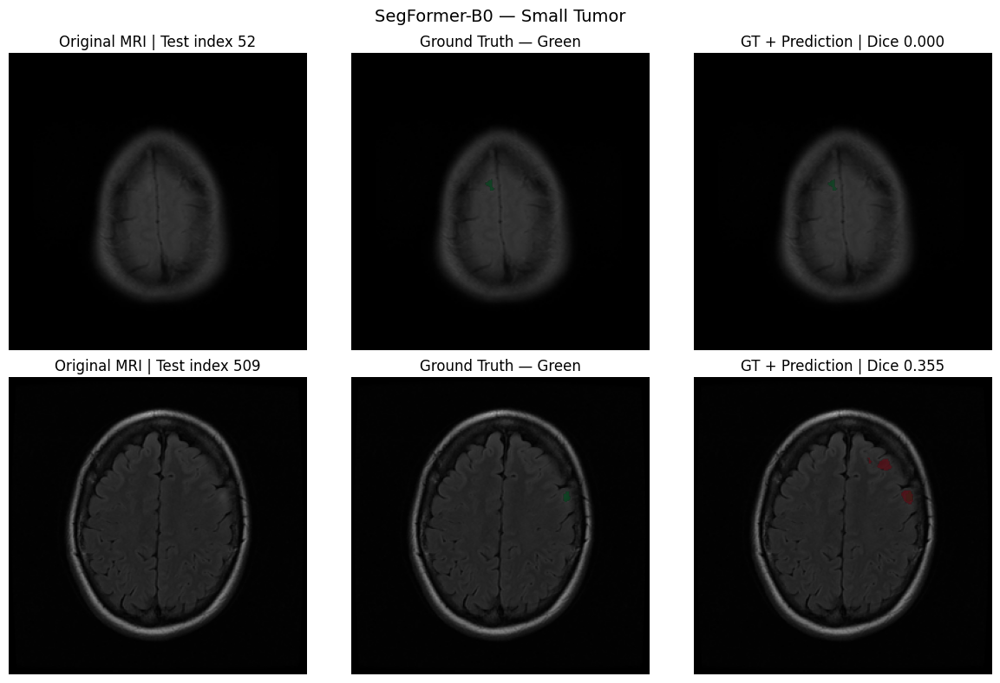

Saved: /content/drive/MyDrive/BrainTumorSegmentation/results/final_audit/hard_cases/small_tumor.png


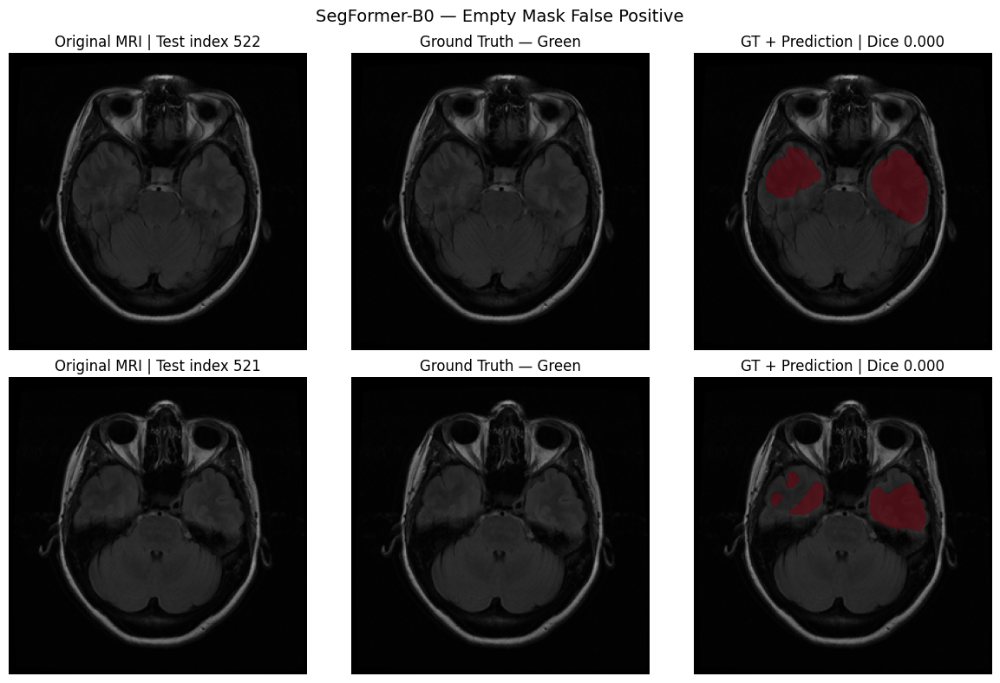

Saved: /content/drive/MyDrive/BrainTumorSegmentation/results/final_audit/hard_cases/empty_mask_false_positive.png


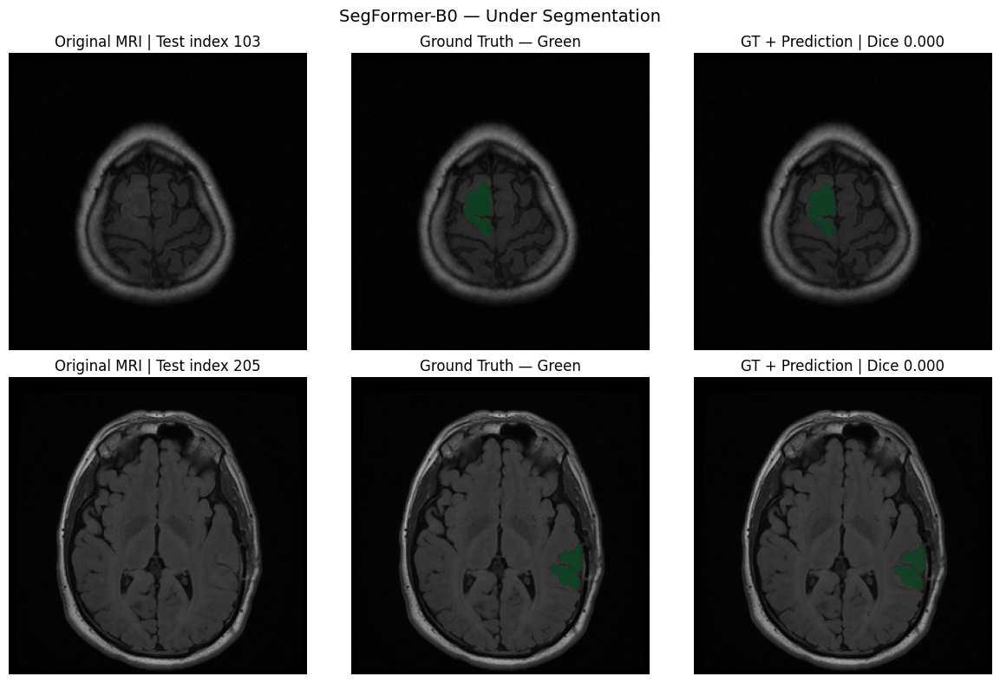

Saved: /content/drive/MyDrive/BrainTumorSegmentation/results/final_audit/hard_cases/under_segmentation.png


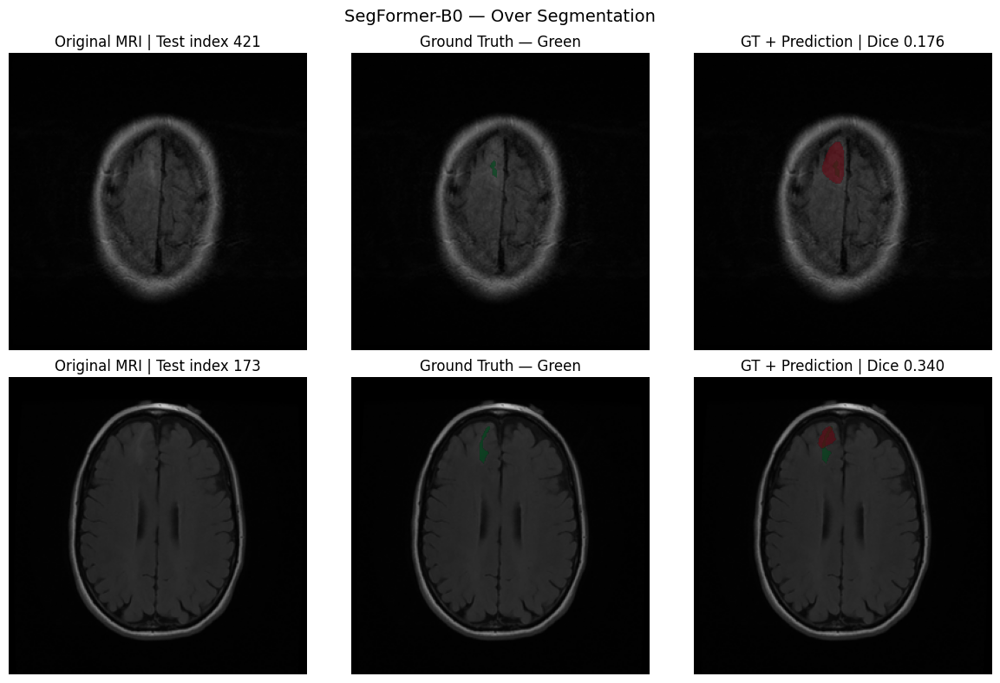

Saved: /content/drive/MyDrive/BrainTumorSegmentation/results/final_audit/hard_cases/over_segmentation.png


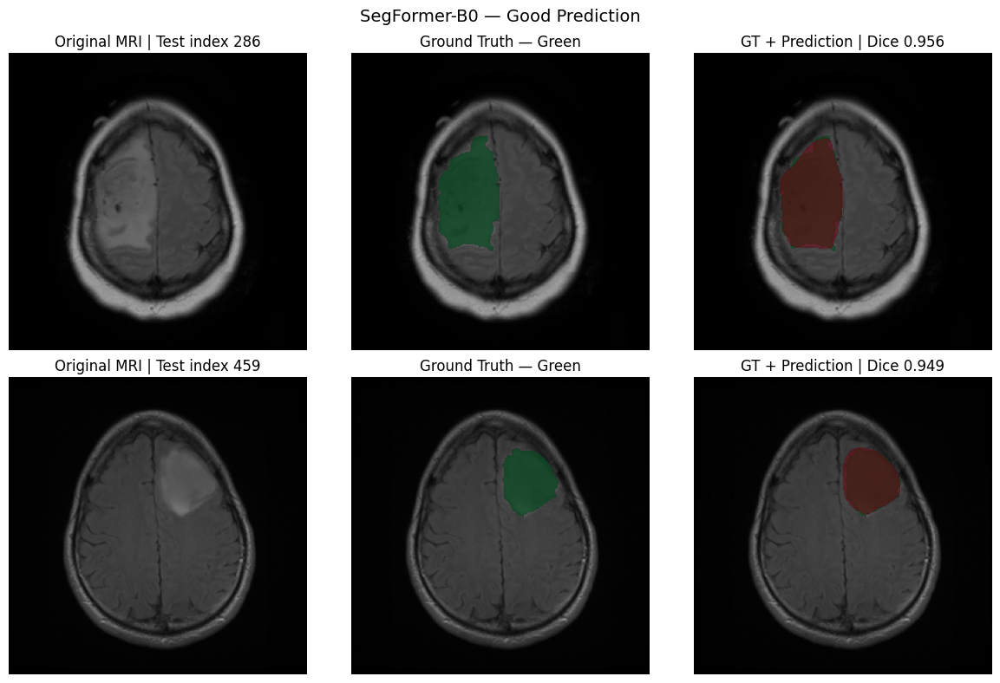

Saved: /content/drive/MyDrive/BrainTumorSegmentation/results/final_audit/hard_cases/good_prediction.png

Hard-case analysis saved to: /content/drive/MyDrive/BrainTumorSegmentation/results/final_audit/hard_cases


In [ ]:

# ============================================================
# FINAL AUDIT 2 — HARD CASES FOR SEGFORMER-B0
# Uses cached final test inference; does not re-evaluate test.
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

assert "test_probs_seg" in globals(), (
    "Run the final SegFormer test evaluation cell first."
)
assert "test_masks_seg" in globals()
assert "test_images_display_seg" in globals()

THRESHOLD_SEG_FINAL = 0.5
hard_dir = os.path.join(AUDIT_DIR, "hard_cases")
os.makedirs(hard_dir, exist_ok=True)

probs = np.asarray(test_probs_seg)
gts = (np.asarray(test_masks_seg) >= 0.5).astype(np.uint8)
imgs = np.asarray(test_images_display_seg)
preds = (probs >= THRESHOLD_SEG_FINAL).astype(np.uint8)

records = []
for i, (gt, pred) in enumerate(zip(gts, preds)):
    gt_area = int(gt.sum())
    pred_area = int(pred.sum())
    inter = int(np.logical_and(gt, pred).sum())
    dice = (2 * inter + 1e-7) / (gt_area + pred_area + 1e-7)

    records.append({
        "test_index": i,
        "gt_pixels": gt_area,
        "pred_pixels": pred_area,
        "dice": float(dice),
        "is_empty_gt": gt_area == 0,
        "area_ratio_pred_to_gt": (
            pred_area / gt_area if gt_area > 0 else np.nan
        )
    })

hard_df = pd.DataFrame(records)

# Small tumor: among positive images, select smallest GT areas.
positive_df = hard_df[hard_df["gt_pixels"] > 0]
small_tumor_indices = positive_df.nsmallest(
    2, "gt_pixels"
)["test_index"].tolist()

# False positives on empty masks: empty GT but nonempty prediction.
empty_fp_indices = hard_df[
    (hard_df["is_empty_gt"]) & (hard_df["pred_pixels"] > 0)
].sort_values("pred_pixels", ascending=False)["test_index"].head(2).tolist()

# Under-segmentation: prediction area much smaller than GT.
under_indices = positive_df[
    positive_df["area_ratio_pred_to_gt"] < 0.7
].sort_values("dice")["test_index"].head(2).tolist()

# Over-segmentation: prediction area much larger than GT.
over_indices = positive_df[
    positive_df["area_ratio_pred_to_gt"] > 1.3
].sort_values("dice")["test_index"].head(2).tolist()

# Good examples: high Dice.
good_indices = positive_df.nlargest(2, "dice")["test_index"].tolist()

case_groups = {
    "small_tumor": small_tumor_indices,
    "empty_mask_false_positive": empty_fp_indices,
    "under_segmentation": under_indices,
    "over_segmentation": over_indices,
    "good_prediction": good_indices,
}

# Save complete per-image case analysis.
hard_df.to_csv(
    os.path.join(hard_dir, "segformer_test_case_analysis.csv"),
    index=False
)

for group_name, indices in case_groups.items():
    if not indices:
        print(f"{group_name}: no matching examples found.")
        continue

    fig, axes = plt.subplots(len(indices), 3, figsize=(12, 4 * len(indices)))
    if len(indices) == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, idx in enumerate(indices):
        img, gt, pred = imgs[idx], gts[idx], preds[idx]
        info = hard_df.loc[hard_df["test_index"] == idx].iloc[0]

        axes[row, 0].imshow(img, cmap="gray", vmin=0, vmax=1)
        axes[row, 0].set_title(
            f"Original MRI | Test index {idx}"
        )

        axes[row, 1].imshow(img, cmap="gray", vmin=0, vmax=1)
        axes[row, 1].imshow(
            np.ma.masked_where(gt == 0, gt),
            cmap="Greens", alpha=0.7, vmin=0, vmax=1
        )
        axes[row, 1].set_title("Ground Truth — Green")

        axes[row, 2].imshow(img, cmap="gray", vmin=0, vmax=1)
        axes[row, 2].imshow(
            np.ma.masked_where(gt == 0, gt),
            cmap="Greens", alpha=0.65, vmin=0, vmax=1
        )
        axes[row, 2].imshow(
            np.ma.masked_where(pred == 0, pred),
            cmap="Reds", alpha=0.55, vmin=0, vmax=1
        )
        axes[row, 2].set_title(
            f"GT + Prediction | Dice {info['dice']:.3f}"
        )

        for ax in axes[row]:
            ax.axis("off")

    fig.suptitle(
        f"SegFormer-B0 — {group_name.replace('_', ' ').title()}",
        fontsize=14
    )
    plt.tight_layout()

    save_path = os.path.join(hard_dir, f"{group_name}.png")
    plt.savefig(save_path, dpi=180, bbox_inches="tight")
    plt.show()
    print("Saved:", save_path)

print("\nHard-case analysis saved to:", hard_dir)


In [ ]:

import os
import pandas as pd

RESULTS_DIR = (
    "/content/drive/MyDrive/BrainTumorSegmentation/results"
)

files_to_check = [
    "unet_from_scratch_test_metrics.csv",
    "unet_scratch_final_metrics.csv",
    "unet_model_comparison.csv",
    "final_model_comparison.csv",
]

for filename in files_to_check:
    path = os.path.join(RESULTS_DIR, filename)

    print("\n" + "=" * 65)
    print("FILE:", filename)

    if not os.path.exists(path):
        print("File not found.")
        continue

    df = pd.read_csv(path)
    print("Columns:", df.columns.tolist())
    print(df.to_string(index=False))



FILE: unet_from_scratch_test_metrics.csv
Columns: ['has_tumor', 'dice', 'iou', 'predicted_pixels', 'true_pixels', 'intersection']
 has_tumor     dice      iou  predicted_pixels  true_pixels  intersection
     False 0.000000 0.000000              1035            0             0
     False 0.000000 0.000000               368            0             0
     False 0.000000 0.000000               323            0             0
     False 0.000000 0.000000               140            0             0
     False 0.000000 0.000000               657            0             0
     False 0.000000 0.000000              1462            0             0
     False 0.000000 0.000000              2239            0             0
     False 0.000000 0.000000              2572            0             0
     False 0.000000 0.000000              3209            0             0
     False 0.000000 0.000000              4241            0             0
     False 0.000000 0.000000              5110         


# Final Model Evaluation and Comparison
## Brain Tumor Segmentation Using MRI

This section presents the final evaluation of three segmentation models:
- U-Net trained from scratch
- Pretrained U-Net with ResNet34 encoder
- SegFormer-B0

All models are evaluated on the same held-out test set. Each model uses a threshold selected using the validation set only. The test set is reserved for final evaluation.

The comparison focuses on Positive Dice, Positive IoU, and Empty-mask False Positive Rate (FPR).



## Evaluation Metrics

### 1. Positive Dice Score
The Dice Score measures the overlap between the predicted tumor mask and the ground-truth mask. In this project, Positive Dice is averaged over test images whose ground-truth masks contain tumor pixels.

A higher Dice Score indicates better segmentation overlap.

### 2. Positive Intersection over Union (IoU)
IoU measures the intersection between the predicted mask and the ground-truth mask divided by their union. It is also averaged over images with positive ground-truth masks.

A higher IoU indicates better overlap.

### 3. Empty-mask False Positive Rate
Empty-mask FPR is the fraction of test images with empty ground-truth masks for which the model predicts at least one tumor pixel.

A lower value indicates fewer false-positive predictions on empty-mask images.

### Threshold Selection
The threshold for each model was selected using the validation set and fixed before the final test evaluation. The test set was not used for threshold selection.



## Final Test Results

The following table summarizes the final results obtained on the held-out test set.

| Model | Threshold | Positive Dice ↑ | Positive IoU ↑ | Empty-mask FPR ↓ |
|---|---:|---:|---:|---:|
| U-Net from Scratch | 0.8 | 0.4149 | 0.3213 | 0.6886 |
| Pretrained U-Net (ResNet34) | 0.6 | 0.7271 | 0.6213 | 0.2657 |
| SegFormer-B0 | 0.5 | 0.7205 | 0.6081 | 0.2057 |

**Test set:** 523 MRI images, including 173 images with positive masks and 350 images with empty masks.

↑ Higher is better. ↓ Lower is better.


,model,threshold,positive_dice,positive_iou,empty_mask_fpr
0,U-Net from scratch,0.8,0.4149,0.3213,0.6886
1,Pretrained U-Net (ResNet34),0.6,0.7271,0.6213,0.2657
2,SegFormer-B0,0.5,0.7205,0.6081,0.2057


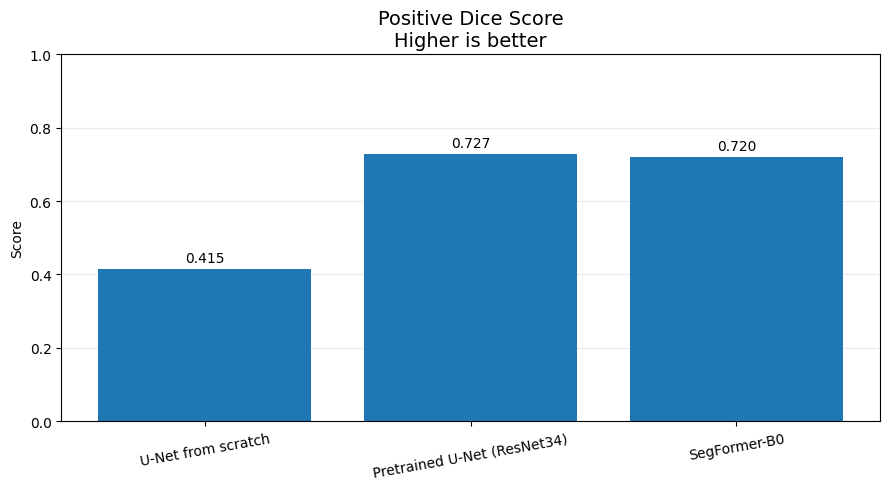

Saved: /content/drive/MyDrive/BrainTumorSegmentation/results/figures/positive_dice_comparison.png


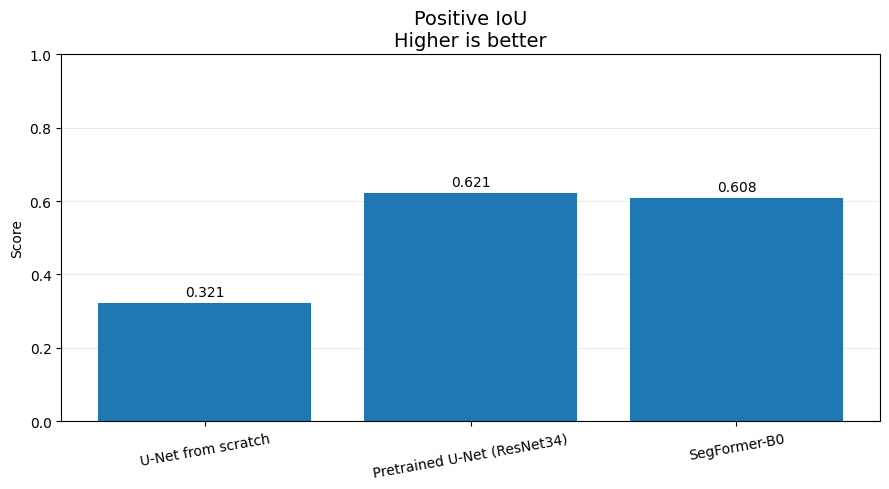

Saved: /content/drive/MyDrive/BrainTumorSegmentation/results/figures/positive_iou_comparison.png


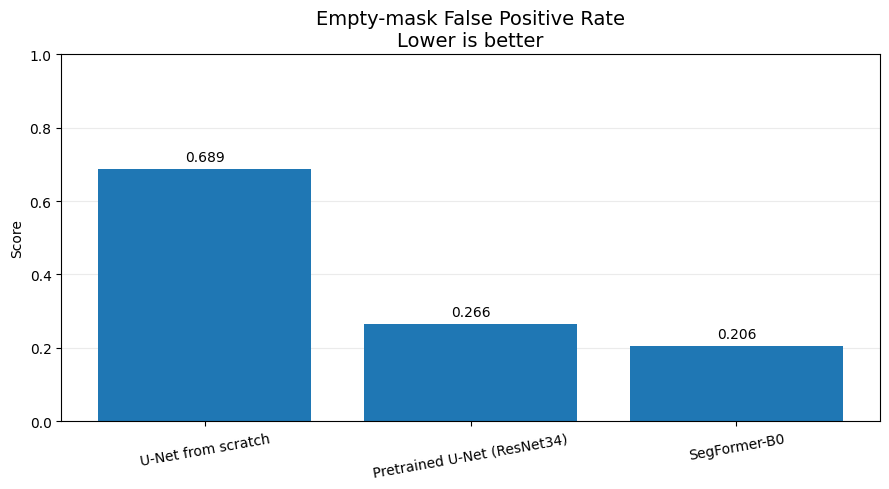

Saved: /content/drive/MyDrive/BrainTumorSegmentation/results/figures/empty_mask_fpr_comparison.png


In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = "/content/drive/MyDrive/BrainTumorSegmentation"
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
FIGURES_DIR = os.path.join(RESULTS_DIR, "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

comparison_path = os.path.join(
    RESULTS_DIR, "final_model_comparison.csv"
)
comparison_df = pd.read_csv(comparison_path)

display(comparison_df.round(4))

plot_metrics = [
    ("positive_dice", "Positive Dice Score", "Higher is better"),
    ("positive_iou", "Positive IoU", "Higher is better"),
    ("empty_mask_fpr", "Empty-mask False Positive Rate", "Lower is better"),
]

for metric, title, note in plot_metrics:
    fig, ax = plt.subplots(figsize=(9, 5))

    bars = ax.bar(comparison_df["model"], comparison_df[metric])
    ax.set_title(f"{title}\n{note}", fontsize=14)
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", rotation=10)

    for bar, value in zip(bars, comparison_df[metric]):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.02,
            f"{value:.3f}",
            ha="center",
            fontsize=10
        )

    plt.tight_layout()

    filename = f"{metric}_comparison.png"
    output_path = os.path.join(FIGURES_DIR, filename)
    plt.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.show()

    print("Saved:", output_path)



## Results Analysis

The pretrained U-Net with a ResNet34 encoder achieved the highest Positive Dice and Positive IoU among the three evaluated models.

SegFormer-B0 achieved the lowest Empty-mask FPR, indicating fewer false-positive predictions on test images with empty ground-truth masks.

The U-Net trained from scratch achieved lower overlap scores than both pretrained approaches in this experiment.

These results show that the preferred model depends on the evaluation objective. Dice and IoU measure segmentation overlap, whereas Empty-mask FPR measures false-positive behavior on empty-mask images. No single metric fully describes model performance.


empty mask false positive


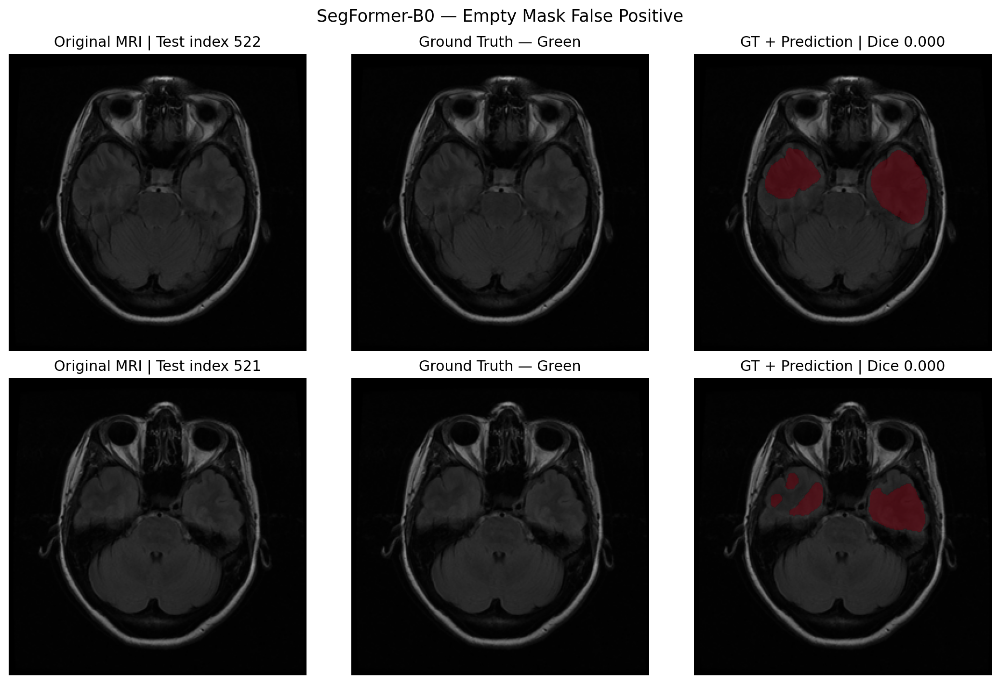

good prediction


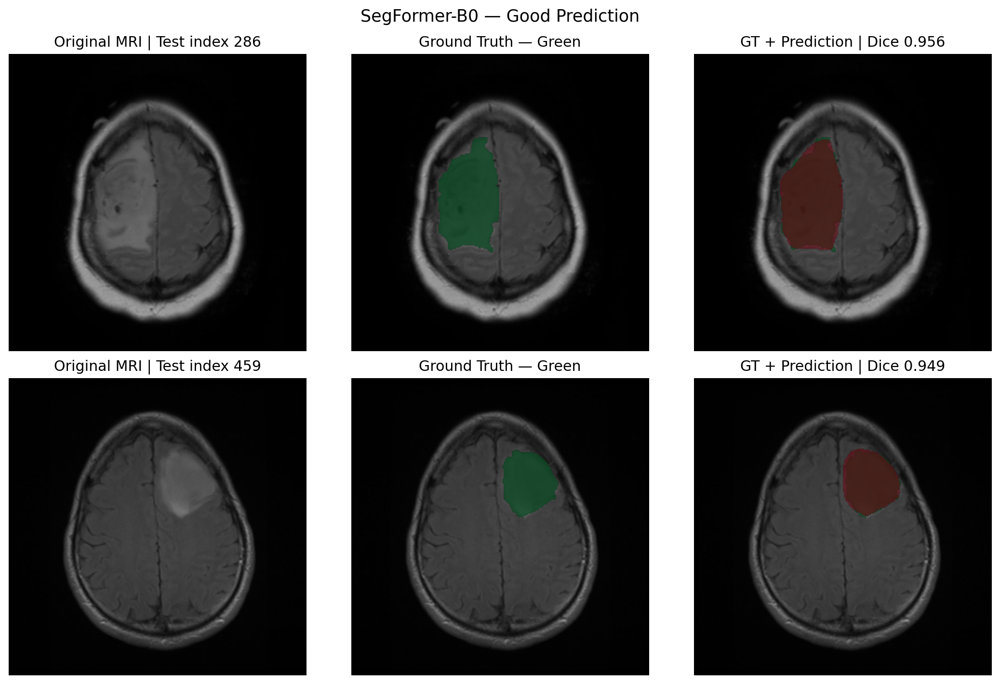

over segmentation


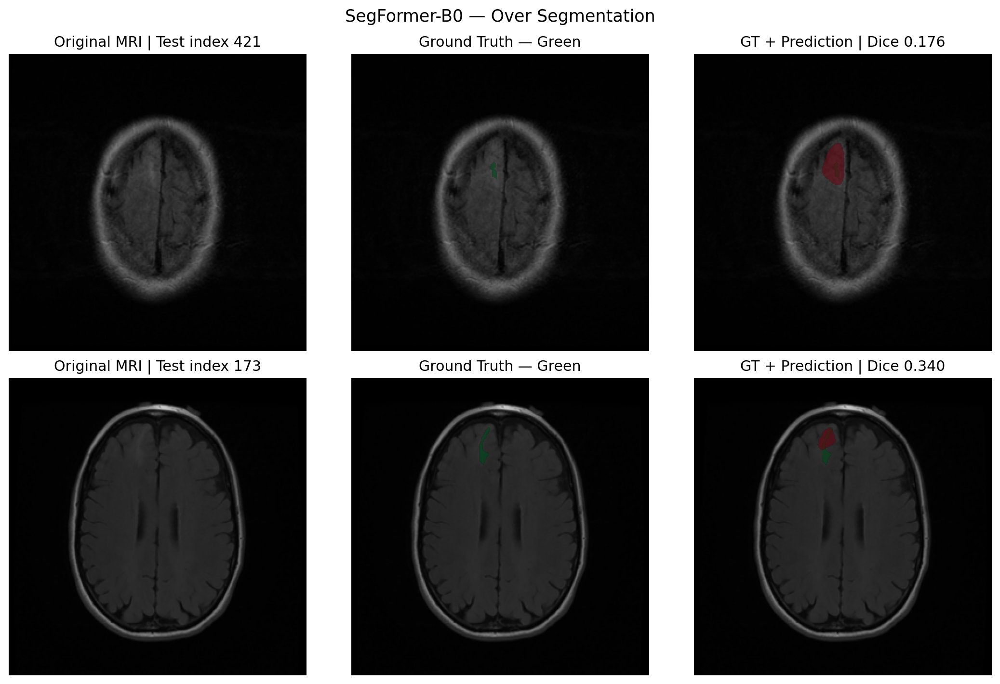

small tumor


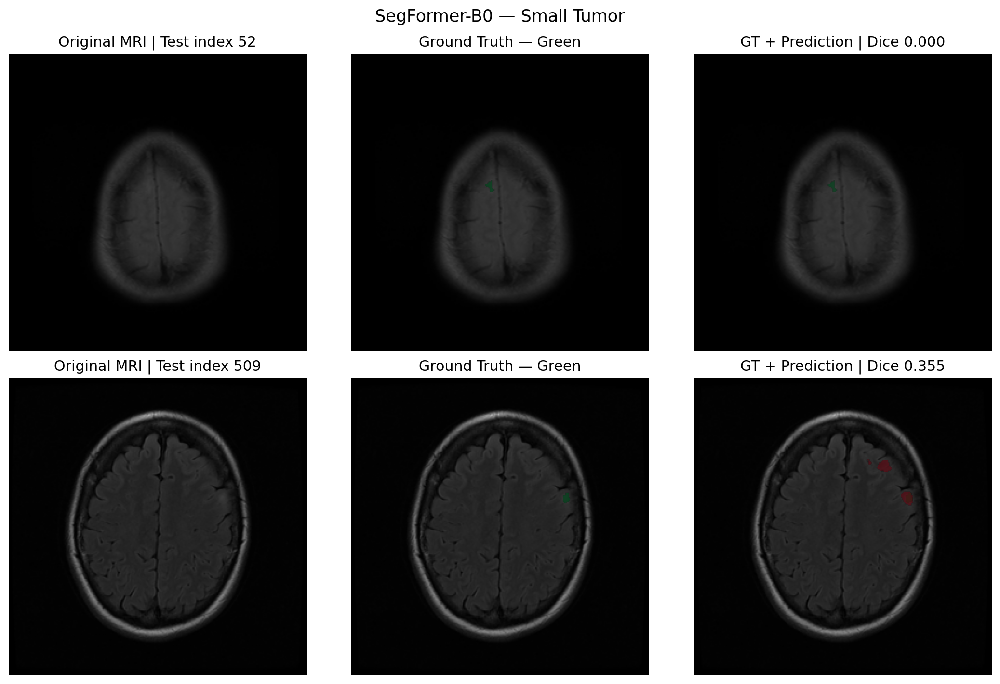

under segmentation


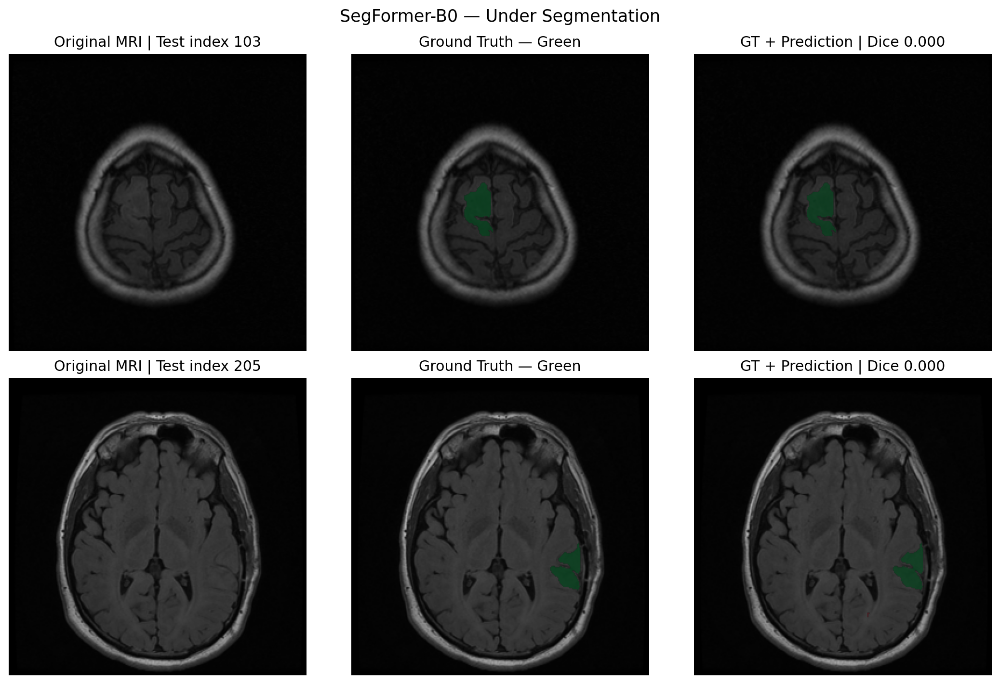

In [ ]:

from IPython.display import display, Image

HARD_CASES_DIR = os.path.join(
    RESULTS_DIR, "final_audit", "hard_cases"
)

if os.path.isdir(HARD_CASES_DIR):
    image_files = sorted([
        f for f in os.listdir(HARD_CASES_DIR)
        if f.lower().endswith(".png")
    ])

    for filename in image_files:
        print(filename.replace("_", " ").replace(".png", ""))
        display(Image(
            filename=os.path.join(HARD_CASES_DIR, filename),
            width=850
        ))
else:
    print("Hard-case figures folder was not found:", HARD_CASES_DIR)


In [ ]:

from pathlib import Path
from google.colab import drive

# Connect Google Drive
drive.mount("/content/drive")

BASE = Path("/content/drive/MyDrive")
PROJECT = BASE / "BrainTumorSegmentation"

print("Project folder exists:", PROJECT.exists())

if PROJECT.exists():
    print("\nProject contents:")
    for item in PROJECT.iterdir():
        print("DIR " if item.is_dir() else "FILE", item.name)

    print("\nSearching for result CSVs and model checkpoints...")
    keywords = (
        "comparison", "per_image", "scratch",
        "segformer", "pretrained", ".pth", ".pt"
    )

    matches = []
    for path in PROJECT.rglob("*"):
        if path.is_file() and any(
            key in path.name.lower() for key in keywords
        ):
            matches.append(path)

    if matches:
        for path in matches:
            print(path)
    else:
        print("No matching files found inside the project folder.")
else:
    print("\nProject folder not found at the expected location.")
    print("Folders in MyDrive:")
    for item in BASE.iterdir():
        print("DIR " if item.is_dir() else "FILE", item.name)


Mounted at /content/drive
Project folder exists: True

Project contents:
DIR  checkpoints
DIR  results
DIR  exported_model

Searching for result CSVs and model checkpoints...
/content/drive/MyDrive/BrainTumorSegmentation/checkpoints/unet_from_scratch_best.pth
/content/drive/MyDrive/BrainTumorSegmentation/checkpoints/unet_resnet34_pretrained_best.pth
/content/drive/MyDrive/BrainTumorSegmentation/checkpoints/segformer_b0_best.pth
/content/drive/MyDrive/BrainTumorSegmentation/results/unet_from_scratch_history.csv
/content/drive/MyDrive/BrainTumorSegmentation/results/unet_from_scratch_test_metrics.csv
/content/drive/MyDrive/BrainTumorSegmentation/results/unet_scratch_test_threshold_08.csv
/content/drive/MyDrive/BrainTumorSegmentation/results/unet_scratch_final_metrics.csv
/content/drive/MyDrive/BrainTumorSegmentation/results/unet_resnet34_pretrained_history.csv
/content/drive/MyDrive/BrainTumorSegmentation/results/unet_pretrained_test_per_image.csv
/content/drive/MyDrive/BrainTumorSegmenta

In [ ]:

import pandas as pd
from pathlib import Path
from IPython.display import display

RESULTS_DIR = Path(
    "/content/drive/MyDrive/BrainTumorSegmentation/results"
)

files = {
    "Final Comparison": "final_model_comparison.csv",
    "Pretrained U-Net": "pretrained_unet_final_test_per_image.csv",
    "SegFormer": "segformer_final_test_per_image.csv",
    "Scratch U-Net": "unet_scratch_test_threshold_08.csv",
}

loaded = {}

for name, filename in files.items():
    path = RESULTS_DIR / filename

    print(f"\n{'=' * 60}\n{name}\n{'=' * 60}")

    if not path.exists():
        print("Missing:", path)
        continue

    df = pd.read_csv(path)
    loaded[name] = df

    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    display(df.head(3))

# Display the final comparison clearly
if "Final Comparison" in loaded:
    print("\nFINAL MODEL COMPARISON")
    display(loaded["Final Comparison"])



Final Comparison
Rows: 3
Columns: ['model', 'threshold', 'positive_dice', 'positive_iou', 'empty_mask_fpr']


,model,threshold,positive_dice,positive_iou,empty_mask_fpr
0,U-Net from scratch,0.8,0.414900,0.321300,0.688600
1,Pretrained U-Net (ResNet34),0.6,0.727133,0.621297,0.265714
2,SegFormer-B0,0.5,0.720485,0.608104,0.205714



Pretrained U-Net
Rows: 523
Columns: ['test_index', 'has_tumor', 'ground_truth_pixels', 'predicted_pixels', 'dice', 'iou', 'false_positive_on_empty', 'threshold']


,test_index,has_tumor,ground_truth_pixels,predicted_pixels,dice,iou,false_positive_on_empty,threshold
0,0,False,0,0,1.0,1.0,0.0,0.6
1,1,False,0,0,1.0,1.0,0.0,0.6
2,2,False,0,0,1.0,1.0,0.0,0.6



SegFormer
Rows: 523
Columns: ['test_index', 'has_tumor', 'ground_truth_pixels', 'predicted_pixels', 'dice', 'iou', 'false_positive_on_empty', 'threshold']


,test_index,has_tumor,ground_truth_pixels,predicted_pixels,dice,iou,false_positive_on_empty,threshold
0,0,False,0,0,1.0,1.0,0.0,0.5
1,1,False,0,0,1.0,1.0,0.0,0.5
2,2,False,0,0,1.0,1.0,0.0,0.5



Scratch U-Net
Rows: 523
Columns: ['has_tumor', 'dice', 'iou', 'predicted_pixels', 'true_pixels']


,has_tumor,dice,iou,predicted_pixels,true_pixels
0,False,1.0,1.0,0,0
1,False,0.0,0.0,199,0
2,False,0.0,0.0,35,0



FINAL MODEL COMPARISON


,model,threshold,positive_dice,positive_iou,empty_mask_fpr
0,U-Net from scratch,0.8,0.414900,0.321300,0.688600
1,Pretrained U-Net (ResNet34),0.6,0.727133,0.621297,0.265714
2,SegFormer-B0,0.5,0.720485,0.608104,0.205714


In [ ]:

from pathlib import Path
import pandas as pd
from IPython.display import display

RESULTS_DIR = Path(
    "/content/drive/MyDrive/BrainTumorSegmentation/results"
)
AUDIT_DIR = RESULTS_DIR / "final_audit" / "hard_cases"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

model_files = {
    "Pretrained U-Net ResNet34":
        "pretrained_unet_final_test_per_image.csv",
    "SegFormer-B0":
        "segformer_final_test_per_image.csv",
    "U-Net from scratch":
        "unet_scratch_test_threshold_08.csv",
}

for model_name, filename in model_files.items():
    path = RESULTS_DIR / filename
    if not path.exists():
        print(f"Missing file: {path}")
        continue

    df = pd.read_csv(path)

    # Normalize column names across the models
    if "ground_truth_pixels" in df.columns:
        df["true_pixels"] = df["ground_truth_pixels"]

    if "false_positive_on_empty" not in df.columns:
        df["false_positive_on_empty"] = (
            (~df["has_tumor"].astype(bool))
            & (df["predicted_pixels"] > 0)
        )

    print("\n" + "=" * 65)
    print(model_name)

    # Images that really contain a tumor: lowest Dice first
    positive = df[df["has_tumor"].astype(bool)].copy()
    worst_positive = positive.sort_values(
        "dice", ascending=True
    ).head(10)

    print("\n10 hardest tumor-positive images (lowest Dice):")
    display(worst_positive)

    # Empty ground-truth masks with predicted tumor pixels
    empty = df[~df["has_tumor"].astype(bool)].copy()
    false_positives = empty[
        empty["predicted_pixels"] > 0
    ].sort_values("predicted_pixels", ascending=False)

    print("\n10 strongest false-positive cases on empty images:")
    display(false_positives.head(10))

    # Save case lists for the report
    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    worst_positive.to_csv(
        AUDIT_DIR / f"{safe_name}_hard_positive_cases.csv",
        index=False
    )
    false_positives.to_csv(
        AUDIT_DIR / f"{safe_name}_false_positive_cases.csv",
        index=False
    )

    print("Positive test images:", len(positive))
    print("Empty test images:", len(empty))
    print("False-positive empty images:", len(false_positives))

print("\nSaved error-analysis files to:")
print(AUDIT_DIR)


Missing file: /content/drive/MyDrive/BrainTumorSegmentation/results/pretrained_unet_final_test_per_image.csv
Missing file: /content/drive/MyDrive/BrainTumorSegmentation/results/segformer_final_test_per_image.csv
Missing file: /content/drive/MyDrive/BrainTumorSegmentation/results/unet_scratch_test_threshold_08.csv

Saved error-analysis files to:
/content/drive/MyDrive/BrainTumorSegmentation/results/final_audit/hard_cases


In [ ]:

from pathlib import Path
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/BrainTumorSegmentation")
RESULTS = PROJECT / "results"

print("Project exists:", PROJECT.exists())
print("Results exists:", RESULTS.exists())

if RESULTS.exists():
    print("\nCSV files found:")
    for p in RESULTS.rglob("*.csv"):
        print(p)
else:
    print("\nResults folder not found. Check the Drive mount.")


Project exists: True
Results exists: True

CSV files found:


In [ ]:

from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/BrainTumorSegmentation")

for folder in [PROJECT, PROJECT / "results", PROJECT / "checkpoints"]:
    print(f"\n--- {folder} ---")
    if folder.exists():
        items = list(folder.iterdir())
        print("Items:", len(items))
        for item in items[:30]:
            print(("DIR  " if item.is_dir() else "FILE ") + item.name)
    else:
        print("Folder does not exist")



--- /content/drive/MyDrive/BrainTumorSegmentation ---
Items: 1
DIR  results

--- /content/drive/MyDrive/BrainTumorSegmentation/results ---
Items: 1
DIR  final_audit

--- /content/drive/MyDrive/BrainTumorSegmentation/checkpoints ---
Folder does not exist


In [ ]:

import os

search_roots = [
    "/content/drive/MyDrive/BrainTumorSegmentation",
    "/content/drive/MyDrive"
]

found_files = []
seen = set()

for root in search_roots:
    if not os.path.isdir(root):
        print("Folder not accessible:", root)
        continue

    for current_root, dirs, files in os.walk(root):
        # Avoid searching the same directory twice.
        for filename in files:
            lower = filename.lower()

            if (
                lower.endswith((".pth", ".pt", ".safetensors"))
                and (
                    "segformer" in lower
                    or "checkpoint" in lower
                    or "model" in lower
                    or "best" in lower
                )
            ):
                path = os.path.join(current_root, filename)
                if path not in seen:
                    seen.add(path)
                    found_files.append(path)

if found_files:
    print("Possible model files found:")
    for path in found_files:
        print(path)
else:
    print("No matching model checkpoint found in MyDrive.")


No matching model checkpoint found in MyDrive.


In [ ]:

import os

PROJECT_DIR = "/content/drive/MyDrive/BrainTumorSegmentation"

for folder in ["results", "results/final_audit", "results/final_audit/hard_cases"]:
    path = os.path.join(PROJECT_DIR, folder)

    print(f"\n--- {folder} ---")

    if not os.path.isdir(path):
        print("Folder not found")
        continue

    files = sorted(os.listdir(path))
    if not files:
        print("Folder is empty")
    else:
        for name in files:
            full_path = os.path.join(path, name)
            if os.path.isfile(full_path):
                print(name, "|", os.path.getsize(full_path), "bytes")
            elif os.path.isdir(full_path):
                print(name, "| folder")



--- results ---
Folder not found

--- results/final_audit ---
Folder not found

--- results/final_audit/hard_cases ---
Folder not found


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/BrainTumorSegmentation"
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(RESULTS_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    CHECKPOINT_DIR,
    "segformer_b0_best.pth"
)

print("Checkpoint folder:", CHECKPOINT_DIR)
print("Model exists:", os.path.isfile(MODEL_PATH))
print("Model path:", MODEL_PATH)

Checkpoint folder: /content/drive/MyDrive/BrainTumorSegmentation/checkpoints
Model exists: False
Model path: /content/drive/MyDrive/BrainTumorSegmentation/checkpoints/segformer_b0_best.pth


In [ ]:
import os

print("=== SegFormer objects ===")
for name in [
    "segformer_model",
    "test_probs_seg",
    "test_masks_seg",
    "test_images_display_seg",
    "hard_df",
    "imgs",
    "gts",
    "preds",
]:
    obj = globals().get(name)
    print(f"{name}: {'Available' if obj is not None else 'Not available'}")

print("\n=== Saved results ===")
for name in [
    "segformer_final_test_per_image.csv",
    "final_model_comparison.csv",
    "segformer_test_case_analysis.csv",
]:
    for folder in [
        os.path.join(RESULTS_DIR, "final_audit", "hard_cases"),
        RESULTS_DIR,
    ]:
        path = os.path.join(folder, name)
        if os.path.isfile(path):
            print(path)

=== SegFormer objects ===
segformer_model: Not available
test_probs_seg: Not available
test_masks_seg: Not available
test_images_display_seg: Not available
hard_df: Not available
imgs: Not available
gts: Not available
preds: Not available

=== Saved results ===


In [ ]:
import os

root = "/content/drive/MyDrive/BrainTumorSegmentation"

for current, dirs, files in os.walk(root):
    for name in files:
        if name.lower().endswith((".pth", ".pt", ".safetensors", ".ckpt")):
            print(os.path.join(current, name))


## Qualitative Error Analysis

The qualitative evaluation includes small tumors, false-positive predictions on empty masks, under-segmentation, over-segmentation, and examples of good overlap.

These examples illustrate different model behaviors that may not be fully captured by average metrics. The selected cases are illustrative and should not be interpreted as an independent estimate of overall performance.

In the overlay figures, green represents the ground-truth mask and red represents the predicted mask.



## Conclusion and Limitations

In this experiment, the pretrained U-Net achieved the highest Positive Dice and Positive IoU, while SegFormer-B0 achieved the lowest Empty-mask FPR.

The findings are limited to the dataset, patient-level split, preprocessing pipeline, checkpoints, and validation-selected thresholds used in this study. Performance on other datasets, MRI protocols, or clinical populations has not been established.

The project is an academic medical-image-segmentation experiment. It is not a clinically validated diagnostic system and must not be used as a substitute for assessment by qualified medical professionals.

### Future Work
- Evaluate generalization on an independent external dataset.
- Investigate performance on small tumors and empty-mask false positives.
- Report patient-level uncertainty and confidence intervals.
- Explore additional loss functions and data augmentation strategies.
